# Forward-Facing Sonar and Tournament Outcomes in the Bassmaster Elite Series (2012–2026)

## INSY 7130 Final Project

**Author:** Joshua Etherton  
**Course:** INSY 7130  
**Dataset:** `bass_with_limits.csv`

### Executive overview

This report compares **tournament-level catch outcomes** across observed event-rule categories. One row per tournament—not one row per angler—is the unit for the main comparisons. The primary outcome is the tournament median of anglers’ average fish weight among anglers who caught at least one fish. It is less mechanically tied to the number of competition days than cumulative weight, but still depends on fishery, high-grading, event format, and who remains in the field.

**Executed headline result:** Among 19 Elite tournaments labelled `No FFS Existed` and 81 labelled `Yes (Unrestricted)`, the observed difference in tournament median average fish weight (unrestricted minus no-FFS-era) was **+0.256 lb per fish**. The 5,000-resample tournament bootstrap 95% percentile interval was **−0.011 to +0.492 lb per fish**. It includes zero, and the groups share no calendar years; the contrast is not a causal estimate. The restricted permutation was not run because no pre-specified waterbody × event-format × estimated-duration × three-year stratum contained both labels. The 2026 extract and other labels are summarized separately.

`Allowed_FFS` records a tournament rule or competitive environment, **not an individual angler’s sonar use**. Differences are associations, not causal effects. Calendar time, tournament scheduling, and waterbody selection overlap strongly with FFS status.

# 1. Introduction

## 1.1 Background

Forward-facing sonar (FFS) is a technology used in modern competitive bass fishing. This project examines tournament records and event-level FFS rule labels in the supplied 2012–2026 compilation. The dataset does not identify whether an individual angler used sonar.

## 1.2 Central research question

**After accounting for tournament structure, time, and fishery differences, are tournament-level catch outcomes different under different forward-facing sonar rules, and are those differences consistent across fisheries?**

## 1.3 Scope and interpretation

`Allowed_FFS` is an event rule or competitive-environment label. It is not an individual treatment or a record of actual device use. This observational dataset cannot identify a causal effect of sonar use. Rule categories are closely aligned with years, while tournament calendars and waterbody assignments also change over time.

The data contain three distinct units: (1) angler–tournament records, (2) tournaments/events, and (3) waterbodies with repeated tournament visits. Anglers within an event share conditions and rules; anglers also recur across events. Inferential comparisons therefore aggregate to one row per event. Repeated waterbodies remain a source of dependence and are examined separately.

## 1.4 Planned course methods

The main evidence uses tournament-level bootstrap intervals. A restricted permutation procedure is evaluated only if its within-stratum label-exchangeability conditions are supportable. The notebook also uses annual and repeated-waterbody baselines, scaled fishery similarity and clustering, and tournament-level anomaly detection. Regression is not the primary method.


# 2. Data Source and Reproducibility

## 2.1 Source

The project folder contains a crawler that retrieves tournament result pages from [Bassmaster Fantasy Tournament Results](https://bassmasterfantasy.com/TournamentResultsList.aspx); each `Source_URL` in the data points to a tournament detail page. The crawler records place, angler identifier, fish count, weight, event URL, and related score fields.

The [Bassmaster tournament explainer](https://www.bassmaster.com/news/how-bassmaster-elite-tournaments-work/) describes a five-bass daily weigh-in and a field cut after two days. B.A.S.S. announced 2025 technology standards in its [2025 sonar standardization announcement](https://www.bassmaster.com/news/b-a-s-s-announces-technology-standardization-for-elite-series-classic/) and the subsequent [2026 live-sonar rule change](https://www.bassmaster.com/elite/news/b-a-s-s-announces-live-sonar-rule-change-for-2026-elite-series/). Those announcements establish that the rule environment changed; they do not prove an angler’s actual sonar use.

The result pages are a public results source, not an official Bassmaster rulebook. The `Allowed_FFS` labels come from the supplied event inventory; they are not inferred from angler equipment use.

## 2.2 Observation unit

Each CSV row represents one angler’s **cumulative** result in one tournament. `Tournament_ID` repeats in different years, so the reproducible event key is `Season_Year` plus `Tournament_ID`. `Player_ID` identifies anglers across events.

## 2.3 Reconstruction completed outside Python

The source data contain cumulative results rather than daily results, so an angler’s cumulative `Fish_Caught` reflects both catch success and the number of rounds the angler was eligible to fish. The estimated event duration and angler-specific cumulative bag limit were reconstructed in **RStudio** and exported to `bass_with_limits.csv`. This notebook imports those columns and validates them; it does not rebuild tournament advancement.

## 2.4 Important variables

| Variable | Meaning in this project |
|---|---|
| `Season_Year`, `Tournament_ID`, `Event_Key` | Season, source tournament ID, and unique season–tournament key |
| `Event_Name` | Event category as supplied: Elite Series, Bassmaster Classic, or Angler of the Year Championship |
| `Allowed_FFS` | Event-level rule/environment label; not actual individual use |
| `Place`, `Player_ID`, `Angler_Name` | Angler’s final position and identity |
| `Fish_Caught`, `Weight_Oz`, `Weight_Lbs_Calculated` | Cumulative event catch and recorded weight |
| `Waterbody`, `Month`, `Tournament_Dates`, `Location` | Event descriptors; some fields are missing |
| `winner_fish_caught`, `event_days`, `event_bag_limit` | Winner’s cumulative fish count, **estimated** event duration (days), and `event_days * 5` |
| `rule_based_days` | Days implied by event format and final place (Elite Series cuts; full field for Classic and AOY) |
| `minimum_days_from_fish` | Minimum days proven by the cumulative fish count (0–5 fish: 1; 6–10: 2; 11–15: 3; 16–20: 4) |
| `initial_days_fished` | Maximum of `rule_based_days` and `minimum_days_from_fish` |
| `days_fished` | Estimated eligible days after the within-tournament ranking-consistency correction |
| `bag_limit` | Estimated angler-specific cumulative bag limit, `days_fished * 5` |
| `proportion_bag_limit`, `percent_bag_limit` | `Fish_Caught / bag_limit` (0–1) and the same value multiplied by 100 |
| `reached_bag_limit` | Whether `Fish_Caught == bag_limit` |
| `Source_URL` | Tournament result-page URL retained for auditing |

## 2.5 Known limitations of the source data

Observed result rows do not provide daily catches, individual equipment use, environmental conditions, verified days competed, or the complete event-specific advancement rules. The reconstructed `days_fished` and `bag_limit` values are **estimates**, not official records; see Section 5 and Section 12.

## 3. Data Preparation and Quality Audit

The next cells load the CSV exported from RStudio, verify the imported reconstruction columns, run bag-limit validation checks, and flag questionable rows without silently deleting them. The primary analysis excludes the single negative-weight record.

### 3.1 Imports and reproducibility settings

The random seed is 7130. Bootstrap and permutation procedures are configured for 5,000 repetitions; permutation execution is conditional on finding defensible mixed-label strata. Clustering uses the same fixed random state. Isolation Forest contamination values are treated as review thresholds rather than probabilities that a record is erroneous.


In [99]:
import sys
import platform
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

RANDOM_SEED = 7130
BOOTSTRAP_REPS = 5_000
PERMUTATION_REPS = 5_000
CLUSTER_RANDOM_STATE = RANDOM_SEED
ANOMALY_CONTAMINATION_LEVELS = (0.03, 0.05)
rng = np.random.default_rng(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

FFS_ORDER = [
    "No FFS Existed",
    "Yes (Unrestricted)",
    "Yes (Restricted)",
    "No",
    "allowed",
    "unavailable",
    "Unknown",
]
FFS_COLORS = {
    "No FFS Existed": "#4C78A8",
    "Yes (Unrestricted)": "#F58518",
    "Yes (Restricted)": "#54A24B",
    "No": "#B279A2",
    "allowed": "#E45756",
    "unavailable": "#9D9DA1",
    "Unknown": "#BAB0AC",
}

candidate_paths = []
for base in [Path.cwd(), *Path.cwd().parents]:
    candidate_paths.extend(
        [base / "Bass Project" / "bass_with_limits.csv", base / "bass_with_limits.csv"]
    )
DATA_PATH = next((path for path in candidate_paths if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not locate bass_with_limits.csv. Expected it in the project folder "
        "or beside this notebook."
    )
DATA_FILENAME = DATA_PATH.name


### 3.2 Load data

The original rows are retained as `df_raw`. The estimated event duration and angler-specific cumulative limits were reconstructed in RStudio and are imported unchanged; no tournament advancement, bag limit, or days fished is inferred in Python. Numeric fields are parsed explicitly, and all later exclusions are represented by flags and the sample-flow table.

In [100]:
df_raw = pd.read_csv(DATA_PATH)
stored_avg_fish_weight = pd.to_numeric(
    df_raw["Avg_Fish_Weight"], errors="coerce"
)
df = df_raw.copy()

numeric_columns = [
    "Season_Year", "Tournament_ID", "Place", "Player_ID", "Fish_Caught",
    "Weight_Oz", "Weight_Lbs_Calculated", "Fantasy_Points",
    "winner_fish_caught", "event_days", "event_bag_limit", "rule_based_days",
    "minimum_days_from_fish", "initial_days_fished", "days_fished", "bag_limit",
    "proportion_bag_limit", "percent_bag_limit",
]
for column in numeric_columns:
    if column in df:
        df[column] = pd.to_numeric(df[column], errors="coerce")

if "reached_bag_limit" in df:
    df["reached_bag_limit"] = (
        df["reached_bag_limit"].astype(str).str.upper()
        .map({"TRUE": True, "FALSE": False}).astype("boolean")
    )
df["Negative_Weight_Flag"] = (
    df["Weight_Oz"].lt(0) | df["Weight_Lbs_Calculated"].lt(0)
).fillna(False)
df["Avg_Fish_Weight"] = np.nan
valid_avg_mask = (
    df["Fish_Caught"].gt(0)
    & df["Weight_Lbs_Calculated"].ge(0)
    & df["Weight_Lbs_Calculated"].notna()
)
df.loc[valid_avg_mask, "Avg_Fish_Weight"] = (
    df.loc[valid_avg_mask, "Weight_Lbs_Calculated"]
    / df.loc[valid_avg_mask, "Fish_Caught"]
)
df["Missing_Month_Flag"] = df["Month"].isna()

# Standardize detailed FFS labels before creating categories
df["Allowed_FFS"] = (
    df["Allowed_FFS"]
    .fillna("Unknown")
    .astype("string")
    .str.strip()
    .replace({
        "allowed": "Yes (Unrestricted)"
    })
)

# Create simplified FFS classification
ffs_mapping = {
    "Yes (Unrestricted)": "Yes",
    "Yes (Restricted)": "Yes",
    "No": "No",
    "No FFS Existed": "No",
    "unavailable": "Unavailable",
}

unmapped_ffs = sorted(
    set(df["Allowed_FFS"].dropna().unique())
    - set(ffs_mapping)
)

if unmapped_ffs:
    raise ValueError(
        f"Unmapped FFS labels: {unmapped_ffs}"
    )

df["FFS_Simple"] = (
    df["Allowed_FFS"]
    .map(ffs_mapping)
)

# Apply the desired order to the detailed labels
observed_ffs = df["Allowed_FFS"].unique().tolist()

ffs_categories = [
    value
    for value in FFS_ORDER
    if value in observed_ffs
]

ffs_categories.extend(
    sorted(
        set(observed_ffs)
        - set(ffs_categories)
    )
)

df["Allowed_FFS"] = pd.Categorical(
    df["Allowed_FFS"],
    categories=ffs_categories,
    ordered=True
)

# Apply an explicit order to the simplified labels
simple_ffs_order = [
    "No",
    "Yes",
    "Unavailable",
]

df["FFS_Simple"] = pd.Categorical(
    df["FFS_Simple"],
    categories=simple_ffs_order,
    ordered=True
)

print(f"Loaded {len(df):,} angler–tournament rows and {df.shape[1]} columns from {DATA_PATH}")
print(f"Observed FFS labels, kept distinct: {ffs_categories}")
print(f"Random seed: {RANDOM_SEED:,}; bootstrap reps: {BOOTSTRAP_REPS:,}; permutation reps: {PERMUTATION_REPS:,}")

print("Detailed FFS categories:")
print(df["Allowed_FFS"].value_counts(dropna=False))

print("\nSimplified FFS categories:")
print(df["FFS_Simple"].value_counts(dropna=False))

print("\nDetailed-to-simple mapping:")
display(
    pd.crosstab(
        df["Allowed_FFS"],
        df["FFS_Simple"],
        dropna=False
    )
)

assert "allowed" not in (
    df["Allowed_FFS"]
    .astype("string")
    .unique()
)

Loaded 13,968 angler–tournament rows and 41 columns from /Users/joshuaetherton/Library/CloudStorage/OneDrive-AuburnUniversity/Auburn/School/Grad_School/Current/Data Mining/Bass Project/bass_with_limits.csv
Observed FFS labels, kept distinct: ['No FFS Existed', 'Yes (Unrestricted)', 'Yes (Restricted)', 'No', 'unavailable']
Random seed: 7,130; bootstrap reps: 5,000; permutation reps: 5,000
Detailed FFS categories:
Allowed_FFS
Yes (Unrestricted)    8688
No FFS Existed        2080
Yes (Restricted)      1530
unavailable           1271
No                     399
Name: count, dtype: int64

Simplified FFS categories:
FFS_Simple
Yes            10218
No              2479
Unavailable     1271
Name: count, dtype: int64

Detailed-to-simple mapping:


FFS_Simple,No,Yes,Unavailable
Allowed_FFS,,,
No FFS Existed,2080,0,0
Yes (Unrestricted),0,8688,0
Yes (Restricted),0,1530,0
No,399,0,0
unavailable,0,0,1271


### 3.2a Validate the imported bag-limit columns

The checks below confirm that the RStudio export contains every reconstruction column and that no angler’s fish count exceeds the assigned estimated limit. Limit-based analyses are used only if the first two counts are zero.

In [101]:
required_columns = [
    "Event_Key",
    "event_days",
    "event_bag_limit",
    "rule_based_days",
    "minimum_days_from_fish",
    "initial_days_fished",
    "days_fished",
    "bag_limit",
    "proportion_bag_limit",
    "percent_bag_limit",
    "reached_bag_limit"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

print("Missing required columns:", missing_columns)

print(
    "Fish counts exceeding assigned bag limits:",
    (df["Fish_Caught"] > df["bag_limit"]).sum()
)

print(
    "Proportions exceeding one:",
    (df["proportion_bag_limit"] > 1).sum()
)

print(
    "Missing reconstructed bag limits:",
    df["bag_limit"].isna().sum()
)

LIMIT_ANALYSIS_OK = (
    not missing_columns
    and (df["Fish_Caught"] > df["bag_limit"]).sum() == 0
    and (df["proportion_bag_limit"] > 1).sum() == 0
)
if not LIMIT_ANALYSIS_OK:
    raise RuntimeError(
        "Reconstructed limits failed validation; do not proceed with limit-based analyses."
    )

expected_event_key = (
    df["Season_Year"].astype("Int64").astype(str) + "_"
    + df["Tournament_ID"].astype("Int64").astype(str)
)
print("Event_Key matches Season_Year + Tournament_ID:", bool(df["Event_Key"].eq(expected_event_key).all()))
print("bag_limit equals 5 * days_fished:", bool(df["bag_limit"].eq(5 * df["days_fished"]).all()))
print("days_fished >= minimum_days_from_fish:", bool(df["days_fished"].ge(df["minimum_days_from_fish"]).all()))
print("days_fished <= event_days:", bool(df["days_fished"].le(df["event_days"]).all()))

event_type_check = (
    df.drop_duplicates("Event_Key")["Event_Name"].value_counts()
    .rename("Unique tournaments").to_frame()
)
display(event_type_check)

Missing required columns: []
Fish counts exceeding assigned bag limits: 0
Proportions exceeding one: 0
Missing reconstructed bag limits: 0
Event_Key matches Season_Year + Tournament_ID: True
bag_limit equals 5 * days_fished: True
days_fished >= minimum_days_from_fish: True
days_fished <= event_days: True


,Unique tournaments
Event_Name,
Elite Series,131
Bassmaster Classic,13
Angler of the Year Championship,6


### 3.3 Create `Event_Key`

A source tournament ID can repeat in later seasons. The following checks test that each season–tournament key maps to a single event category, waterbody, and FFS label. Any exceptions are displayed rather than resolved silently.

In [102]:
event_consistency = (
    df.groupby("Event_Key", observed=True)
    .agg(
        n_event_names=("Event_Name", "nunique"),
        n_waterbodies=("Waterbody", "nunique"),
        n_ffs_statuses=("Allowed_FFS", "nunique"),
        n_seasons=("Season_Year", "nunique"),
    )
)
event_exceptions = event_consistency.query(
    "n_event_names > 1 or n_waterbodies > 1 or n_ffs_statuses > 1 or n_seasons > 1"
)
display(event_consistency.describe().round(2))
print(f"Event keys with metadata consistency exceptions: {len(event_exceptions)}")
display(event_exceptions)


,n_event_names,n_waterbodies,n_ffs_statuses,n_seasons
count,150.0,150.0,150.0,150.0
mean,1.0,1.0,1.0,1.0
std,0.0,0.0,0.0,0.0
min,1.0,1.0,1.0,1.0
25%,1.0,1.0,1.0,1.0
50%,1.0,1.0,1.0,1.0
75%,1.0,1.0,1.0,1.0
max,1.0,1.0,1.0,1.0


Event keys with metadata consistency exceptions: 0


,n_event_names,n_waterbodies,n_ffs_statuses,n_seasons
Event_Key,,,,


### 3.4 Data types and missingness

Targeted summaries show missingness and numeric ranges without `describe(include='all')`. Non-finite values are counted explicitly.

In [103]:
missingness = df.isna().sum().rename("Missing rows").to_frame()
missingness["Missing proportion"] = missingness["Missing rows"] / len(df)
display(missingness.loc[missingness["Missing rows"].gt(0)].sort_values("Missing rows", ascending=False))

numeric_summary = df.select_dtypes(include="number").agg(["count", "min", "median", "max"]).T
numeric_summary["infinite_count"] = [
    int(np.isinf(df[column].dropna()).sum()) for column in numeric_summary.index
]
display(numeric_summary.round(3))

categorical_summary = pd.concat(
    {
        column: df[column].astype("string").value_counts(dropna=False)
        for column in ["Event_Name", "Allowed_FFS", "Month"]
    },
    names=["Variable", "Value"],
).rename("Angler rows").to_frame()
display(categorical_summary)

,Missing rows,Missing proportion
Big_Bag_Points,13815,0.989046
Big_Bass_Points,13804,0.988259
Leader_Bonus,12593,0.901561
Month,1610,0.115263
Avg_Fish_Weight,39,0.002792
Weight_Lbs,1,0.000072
Weight_Oz_Remainder,1,0.000072


,count,min,median,max,infinite_count
Season_Year,13968.0,2012.0,2019.000,2026.000,0
Tournament_ID,13968.0,1.0,6.000,11.000,0
Place,13968.0,1.0,47.000,120.000,0
Player_ID,13968.0,117.0,289.000,530.000,0
Fish_Caught,13968.0,0.0,10.000,20.000,0
Weight_Oz,13968.0,-16.0,500.000,2095.000,0
Big_Bag_Points,153.0,40.0,40.000,40.000,0
Big_Bass_Points,164.0,40.0,40.000,40.000,0
Leader_Bonus,1375.0,5.0,5.000,20.000,0
Fantasy_Points,13968.0,0.0,181.000,400.000,0


Angler rows
Variable    Value                                       
Event_Name  Elite Series                           12963
            Bassmaster Classic                       705
            Angler of the Year Championship          300
Allowed_FFS Yes (Unrestricted)                      8688
            No FFS Existed                          2080
            Yes (Restricted)                        1530
            unavailable                             1271
            No                                       399
Month       Apr                                     2294
            Aug                                     2045
            Jun                                     1951
            Feb                                     1829
            May                                     1631
            <NA>                                    1610
            Mar                                     1385
            Jul                                      761
            Sep                                      292
            Oct                                      170

### 3.5 Duplicate-key review

Independent key checks look for repeated event–angler records. Repeated result URLs are expected within a tournament because the event page is shared by its angler rows; URL reuse across distinct events is checked separately.

In [104]:
df["Event_Player_Duplicate_Flag"] = df.duplicated(
    ["Event_Key", "Player_ID"], keep=False
)
df["Event_Angler_Duplicate_Flag"] = df.duplicated(
    ["Event_Key", "Angler_Name"], keep=False
)

duplicate_audit = pd.DataFrame(
    {
        "Rows": [
            len(df),
            int(df["Missing_Month_Flag"].sum()),
            int(df["Event_Player_Duplicate_Flag"].sum()),
            int(df["Event_Angler_Duplicate_Flag"].sum()),
            int(df["Source_URL"].duplicated(keep=False).sum()),
        ]
    },
    index=[
        "Original rows",
        "Missing Month rows",
        "Repeated Event_Key + Player_ID rows",
        "Repeated Event_Key + Angler_Name rows",
        "Rows sharing a Source_URL",
    ],
)
display(duplicate_audit)
print(
    "Distinct Source_URL values:", df["Source_URL"].nunique(),
    "| URLs spanning multiple Event_Key values:",
    int(df.groupby("Source_URL")["Event_Key"].nunique().gt(1).sum()),
)
display(
    df.loc[df["Event_Player_Duplicate_Flag"] | df["Event_Angler_Duplicate_Flag"],
           ["Event_Key", "Player_ID", "Angler_Name", "Place", "Source_URL"]].head(20)
)

,Rows
Original rows,13968
Missing Month rows,1610
Repeated Event_Key + Player_ID rows,0
Repeated Event_Key + Angler_Name rows,0
Rows sharing a Source_URL,13968


Distinct Source_URL values: 150 | URLs spanning multiple Event_Key values: 0


,Event_Key,Player_ID,Angler_Name,Place,Source_URL


### 3.6 Invalid weight investigation

Negative values are invalid for total catch weight. The flagged record is retained in `df` for review but excluded from the clean analytical rows. No duplicate or review flag alone causes deletion.

In [105]:
negative_weight_rows = df.loc[
    df["Negative_Weight_Flag"],
    [
        "Event_Key", "Season_Year", "Tournament_ID", "Event_Name",
        "Place", "Angler_Name", "Player_ID", "Fish_Caught",
        "Weight_Oz", "Weight_Lbs_Calculated", "Source_URL",
    ],
]
print("Negative Weight_Oz rows:", int(df["Weight_Oz"].lt(0).sum()))
print("Negative Weight_Lbs_Calculated rows:", int(df["Weight_Lbs_Calculated"].lt(0).sum()))
display(negative_weight_rows)

analysis_rows = df.loc[~df["Negative_Weight_Flag"]].copy()


Negative Weight_Oz rows: 1
Negative Weight_Lbs_Calculated rows: 1


,Event_Key,Season_Year,Tournament_ID,Event_Name,Place,Angler_Name,Player_ID,Fish_Caught,Weight_Oz,Weight_Lbs_Calculated,Source_URL
2763,2015_2,2015,2,Elite Series,113,Scott Ashmore,136,0,-16,-1.0,https://bassmasterfantasy.com/TournamentDetail...


### 3.7 Safe derived variables

Average fish weight is calculated only when an angler caught at least one fish and the total weight is nonnegative. Zero-fish anglers remain in the event sample for catch-rate summaries; their average fish weight is undefined.

In [106]:
missing_average_audit = pd.DataFrame(
    {
        "Rows": [
            int(stored_avg_fish_weight.isna().sum()),
            int(
                (
                    stored_avg_fish_weight.isna()
                    & df["Fish_Caught"].eq(0)
                ).sum()
            ),
            int(
                (
                    stored_avg_fish_weight.isna()
                    & df["Weight_Lbs_Calculated"].lt(0)
                ).sum()
            ),
            int(np.isinf(stored_avg_fish_weight.dropna()).sum()),
            int(
                (
                    np.isinf(stored_avg_fish_weight)
                    & df["Fish_Caught"].eq(0)
                    & df["Weight_Lbs_Calculated"].lt(0)
                ).sum()
            ),
            int(df["Avg_Fish_Weight"].isna().sum()),
            int((df["Fish_Caught"].eq(0) & df["Avg_Fish_Weight"].isna()).sum()),
            int((df["Weight_Lbs_Calculated"].lt(0) & df["Avg_Fish_Weight"].isna()).sum()),
            int(
                (
                    df["Avg_Fish_Weight"].isna()
                    & df["Fish_Caught"].gt(0)
                    & df["Weight_Lbs_Calculated"].ge(0)
                ).sum()
            ),
        ]
    },
    index=[
        "Original stored Avg_Fish_Weight missing",
        "Original missing with zero fish",
        "Original missing with negative weight",
        "Original infinite Avg_Fish_Weight values",
        "Infinite value also had zero fish and negative weight",
        "Missing safe Avg_Fish_Weight",
        "Missing because Fish_Caught = 0",
        "Missing with invalid negative total weight",
        "Other missing average-weight rows",
    ],
)
display(missing_average_audit)
print("Infinite safe Avg_Fish_Weight values:", int(np.isinf(df["Avg_Fish_Weight"].dropna()).sum()))


,Rows
Original stored Avg_Fish_Weight missing,38
Original missing with zero fish,38
Original missing with negative weight,0
Original infinite Avg_Fish_Weight values,1
Infinite value also had zero fish and negative weight,1
Missing safe Avg_Fish_Weight,39
Missing because Fish_Caught = 0,39
Missing with invalid negative total weight,1
Other missing average-weight rows,0


Infinite safe Avg_Fish_Weight values: 0


### 3.8 Analysis sample flow

The primary fish-size outcome is undefined for zero-catch rows; those rows remain available for other descriptive event features. The single negative-weight row is excluded from all clean event summaries. Event and waterbody counts below refer to the clean row set before the Elite-only inferential restriction.

In [107]:
duplicate_rows_excluded = 0
rows_missing_primary_outcome = int(analysis_rows["Avg_Fish_Weight"].isna().sum())
flow = pd.DataFrame(
    {
        "Rows / units": [
            len(df),
            int(df["Negative_Weight_Flag"].sum()),
            duplicate_rows_excluded,
            rows_missing_primary_outcome,
            len(analysis_rows),
            analysis_rows["Event_Key"].nunique(),
            analysis_rows["Waterbody"].nunique(),
            analysis_rows["Player_ID"].nunique(),
        ]
    },
    index=[
        "Original angler–tournament rows",
        "Rows flagged/excluded for negative weights",
        "Duplicate rows excluded",
        "Clean rows without primary Avg_Fish_Weight",
        "Rows retained for descriptive analyses",
        "Unique tournaments retained",
        "Unique waterbodies retained",
        "Unique anglers retained",
    ],
)
display(flow)


,Rows / units
Original angler–tournament rows,13968
Rows flagged/excluded for negative weights,1
Duplicate rows excluded,0
Clean rows without primary Avg_Fish_Weight,38
Rows retained for descriptive analyses,13967
Unique tournaments retained,150
Unique waterbodies retained,62
Unique anglers retained,380


# 4. Exploratory Analysis

Exploration describes event coverage and response distributions. These plots are not independent angler-level evidence for an FFS association; the inferential unit remains the tournament.


## 4.1 Tournament coverage by year

Annual event counts are based on unique `Event_Key`, not angler rows.

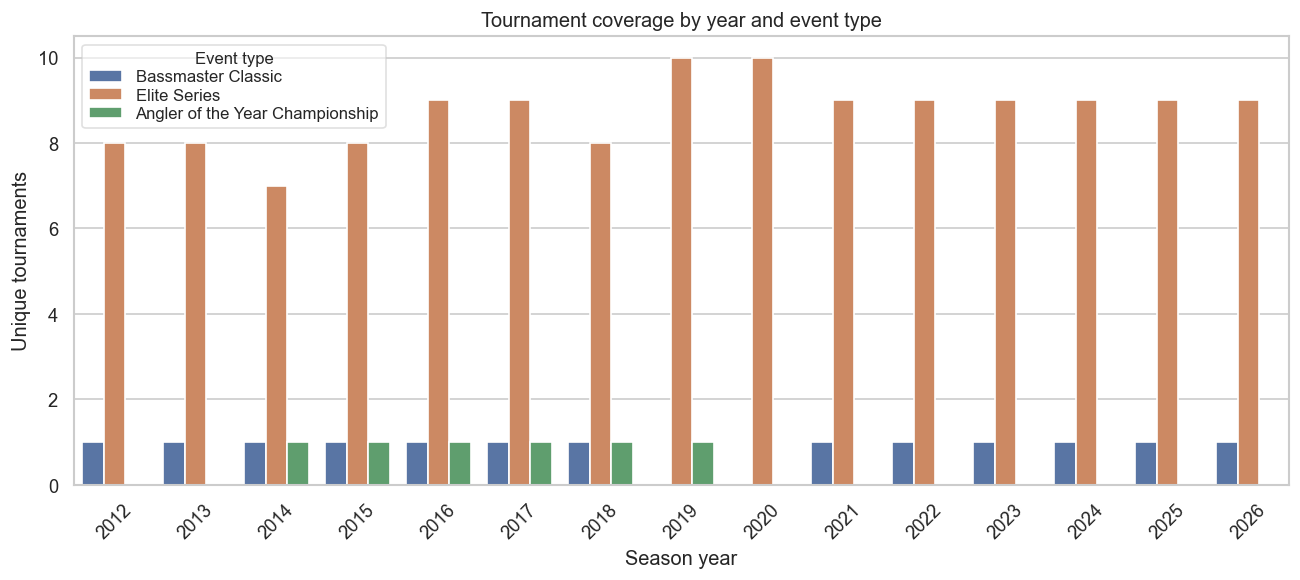

Event_Name,Angler of the Year Championship,Bassmaster Classic,Elite Series
Season_Year,,,
2012,0,1,8
2013,0,1,8
2014,1,1,7
2015,1,1,8
2016,1,1,9
2017,1,1,9
2018,1,1,8
2019,1,0,10
2020,0,0,10


In [108]:
event_frame = analysis_rows.drop_duplicates("Event_Key")
annual_event_counts = (
    event_frame.groupby(["Season_Year", "Event_Name"], observed=True)
    .size().rename("Tournaments").reset_index()
)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=annual_event_counts, x="Season_Year", y="Tournaments",
    hue="Event_Name", errorbar=None
)
plt.title("Tournament coverage by year and event type")
plt.xlabel("Season year")
plt.ylabel("Unique tournaments")
plt.xticks(rotation=45)
# 1. Create the legend with a fully opaque border frame
leg = plt.legend(
    title="Event type", 
    frameon=True,            
    fontsize="small",        
    title_fontsize="small", 
    labelspacing=0.2,       
    facecolor="white",   
    framealpha=1.0,          # Keeps the outer border line fully solid
)
leg.get_frame().set_alpha(0.6) # Sets the background fill to 60% see-through
plt.tight_layout()
plt.show()
display(annual_event_counts.pivot(index="Season_Year", columns="Event_Name", values="Tournaments").fillna(0).astype(int))





**Interpretation.** Event counts vary by season and event type. This matters because event-level sample sizes and schedule composition are unequal; the figure does not measure a technology effect.

## 4.2 Event types

All observed `Event_Name` values are retained. The Bassmaster Classic and Angler of the Year Championship are not pooled into the primary Elite Series analysis.

In [109]:
event_type_counts = (
    analysis_rows.drop_duplicates("Event_Key")["Event_Name"]
    .value_counts().rename("Unique tournaments").to_frame()
)
display(event_type_counts)


,Unique tournaments
Event_Name,
Elite Series,131
Bassmaster Classic,13
Angler of the Year Championship,6


## 4.3 Waterbody coverage

Waterbody counts are counted as unique tournaments, not angler rows.

In [110]:
waterbody_coverage = (
    analysis_rows.drop_duplicates("Event_Key")
    .groupby("Waterbody", observed=True)
    .agg(Unique_Tournaments=("Event_Key", "nunique"), Years=("Season_Year", "nunique"))
    .sort_values(["Unique_Tournaments", "Waterbody"], ascending=[False, True])
)
display(waterbody_coverage.head(25))


,Unique_Tournaments,Years
Waterbody,,
St. Lawrence River,10,10
St. Johns River,8,8
Lake Champlain,7,6
Lake Guntersville,7,6
Mississippi River,7,7
Lake Hartwell,6,5
Lake St. Clair,6,6
Sabine River,6,6
Lake Fork,5,5


## 4.4 FFS status by year

All raw labels are shown separately. `allowed` and `unavailable` are not merged with any other label; `No` is not treated as synonymous with `No FFS Existed`.

Allowed_FFS,No FFS Existed,Yes (Unrestricted),Yes (Restricted),No,unavailable
Season_Year,,,,,
2012,9,0,0,0,0
2013,7,0,0,0,2
2014,6,0,0,0,3
2015,0,8,0,0,2
2016,0,10,0,0,1
2017,0,7,0,0,4
2018,0,8,0,0,2
2019,0,11,0,0,0
2020,0,10,0,0,0


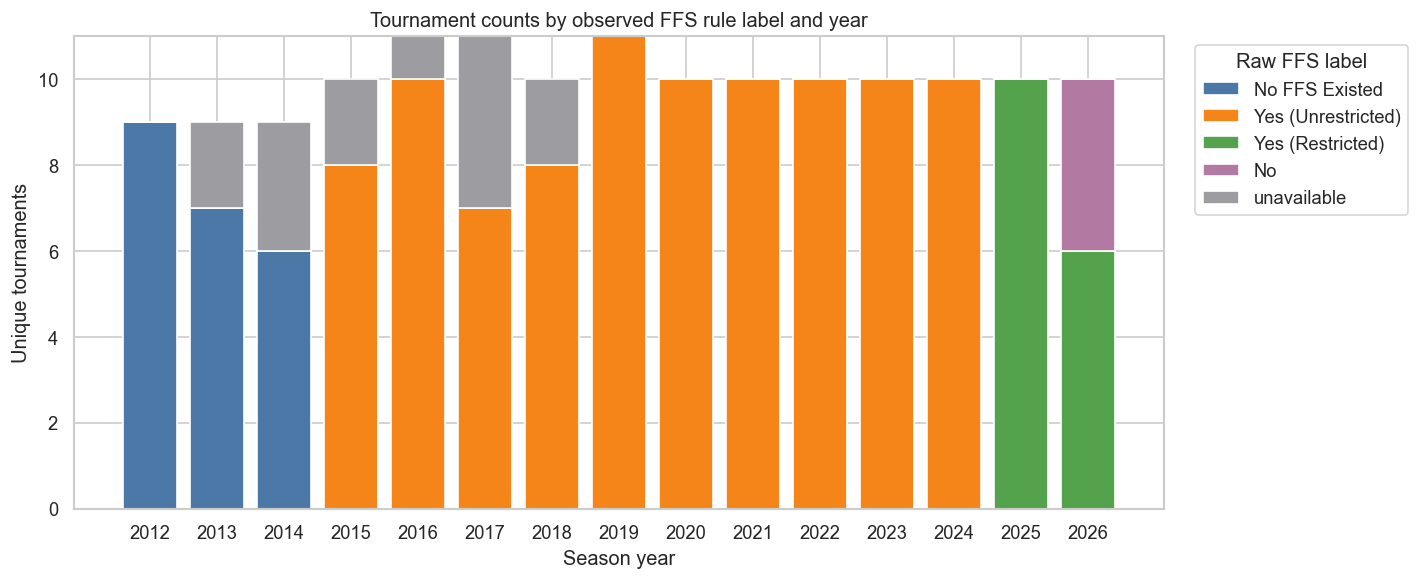

In [111]:
event_status = analysis_rows.drop_duplicates("Event_Key")
ffs_year_counts = (
    event_status.groupby(["Season_Year", "Allowed_FFS"], observed=True)
    .size().rename("Tournaments").reset_index()
)
ffs_year_pivot = ffs_year_counts.pivot(
    index="Season_Year", columns="Allowed_FFS", values="Tournaments"
).fillna(0)
ffs_year_pivot = ffs_year_pivot.reindex(columns=ffs_categories, fill_value=0)
display(ffs_year_pivot.astype(int))

plt.figure(figsize=(12, 5))
bottom = np.zeros(len(ffs_year_pivot))
for label in ffs_year_pivot.columns:
    values = ffs_year_pivot[label].to_numpy()
    plt.bar(
        ffs_year_pivot.index.astype(str), values, bottom=bottom,
        color=FFS_COLORS.get(label, "#BAB0AC"), label=label
    )
    bottom += values
plt.title("Tournament counts by observed FFS rule label and year")
plt.xlabel("Season year")
plt.ylabel("Unique tournaments")
plt.legend(title="Raw FFS label", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


**Interpretation.** The labels are strongly aligned with calendar periods, including distinct unknown/unresolved labels. This limited time overlap is central to the later comparison design and precludes a casual causal reading.

## 4.5 Outcome distributions

The plot uses one tournament-level median per event. The primary outcome is defined only among anglers with positive fish counts.

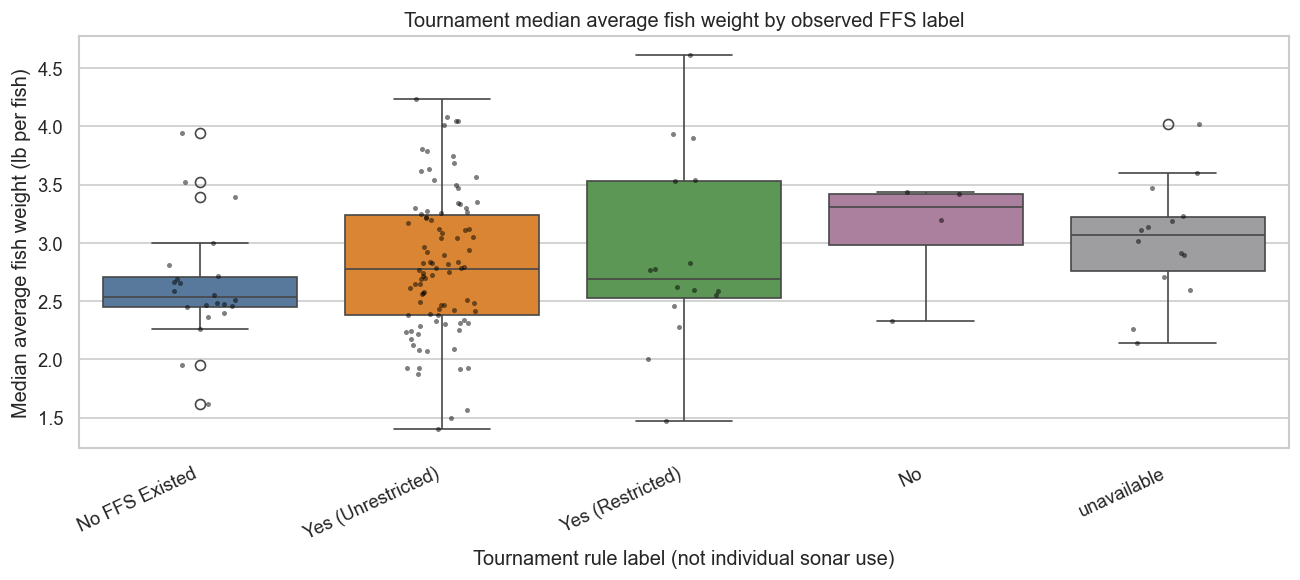

,Tournaments,Median,Mean
Allowed_FFS,,,
No FFS Existed,22,2.532812,2.635090
Yes (Unrestricted),94,2.775240,2.808066
Yes (Restricted),16,2.693899,2.901979
No,4,3.307292,3.096875
unavailable,14,3.066667,3.020749


In [112]:
def safe_event_median(series):
    values = series.dropna()
    return values.median() if len(values) else np.nan

positive = analysis_rows.loc[analysis_rows["Avg_Fish_Weight"].notna()]
descriptive_event_outcomes = (
    analysis_rows.groupby("Event_Key", observed=True)
    .agg(
        Season_Year=("Season_Year", "first"),
        Event_Name=("Event_Name", "first"),
        Allowed_FFS=("Allowed_FFS", "first"),
        Waterbody=("Waterbody", "first"),
    )
    .join(positive.groupby("Event_Key")["Avg_Fish_Weight"].median().rename("Median_Avg_Fish_Weight"))
    .reset_index()
)
plt.figure(figsize=(11, 5))
sns.boxplot(
    data=descriptive_event_outcomes,
    x="Allowed_FFS", y="Median_Avg_Fish_Weight",
    hue="Allowed_FFS", order=ffs_categories, hue_order=ffs_categories,
    palette=FFS_COLORS, legend=False
)
sns.stripplot(
    data=descriptive_event_outcomes, x="Allowed_FFS", y="Median_Avg_Fish_Weight",
    order=ffs_categories, color="black", alpha=0.5, size=3, jitter=0.15
)
plt.title("Tournament median average fish weight by observed FFS label")
plt.xlabel("Tournament rule label (not individual sonar use)")
plt.ylabel("Median average fish weight (lb per fish)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()
display(
    descriptive_event_outcomes.groupby("Allowed_FFS", observed=True)
    .agg(Tournaments=("Event_Key", "nunique"), Median=("Median_Avg_Fish_Weight", "median"),
         Mean=("Median_Avg_Fish_Weight", "mean"))
)


**Interpretation.** The points show between-event variation and category coverage. They do not adjust for year, waterbody, field advancement, or event type; the formal comparisons below use the tournament table and report these overlaps.

## 4.6 Angler-level estimated limit completion (descriptive only)

The figures below describe `proportion_bag_limit`, `percent_bag_limit`, and `reached_bag_limit` across angler–tournament rows. They are **descriptive only**: anglers within a tournament share conditions and are not independent observations, and the denominator is an *estimated* angler-specific cumulative limit. Inferential comparisons later in the notebook use one row per tournament.

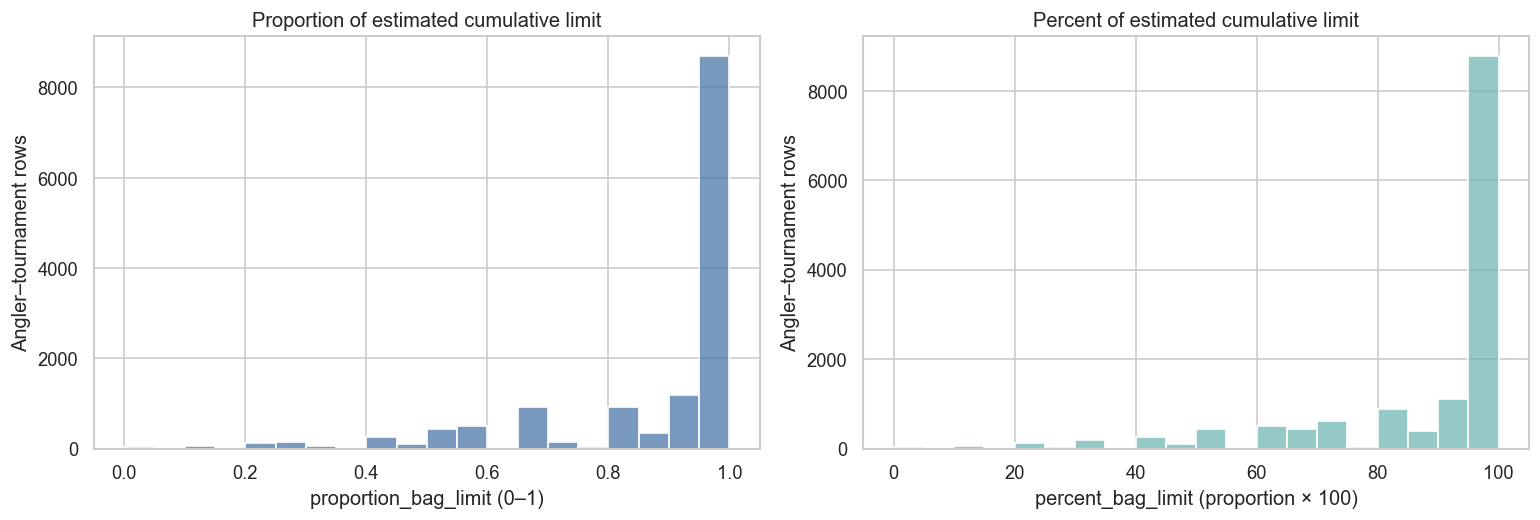

,Angler_Rows,Tournaments,Median_Proportion,Mean_Proportion,Share_Reaching_Limit
Event_Name,,,,,
Elite Series,12962,131,1.000,0.895,0.643
Bassmaster Classic,705,13,0.667,0.674,0.25
Angler of the Year Championship,300,6,1.000,0.908,0.643


In [113]:
limit_rows = analysis_rows.loc[analysis_rows["proportion_bag_limit"].notna()].copy()
event_name_order = [
    name for name in ["Elite Series", "Bassmaster Classic", "Angler of the Year Championship"]
    if name in set(limit_rows["Event_Name"])
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(
    limit_rows, x="proportion_bag_limit", bins=np.linspace(0, 1, 21),
    color="#4C78A8", ax=axes[0]
)
axes[0].set_title("Proportion of estimated cumulative limit")
axes[0].set_xlabel("proportion_bag_limit (0–1)")
axes[0].set_ylabel("Angler–tournament rows")
sns.histplot(
    limit_rows, x="percent_bag_limit", bins=np.linspace(0, 100, 21),
    color="#72B7B2", ax=axes[1]
)
axes[1].set_title("Percent of estimated cumulative limit")
axes[1].set_xlabel("percent_bag_limit (proportion × 100)")
axes[1].set_ylabel("Angler–tournament rows")
plt.tight_layout()
plt.show()

limit_by_event_name = (
    limit_rows.groupby("Event_Name", observed=True)
    .agg(
        Angler_Rows=("Event_Key", "size"),
        Tournaments=("Event_Key", "nunique"),
        Median_Proportion=("proportion_bag_limit", "median"),
        Mean_Proportion=("proportion_bag_limit", "mean"),
        Share_Reaching_Limit=("reached_bag_limit", "mean"),
    )
    .reindex(event_name_order)
)
display(limit_by_event_name.round(3))

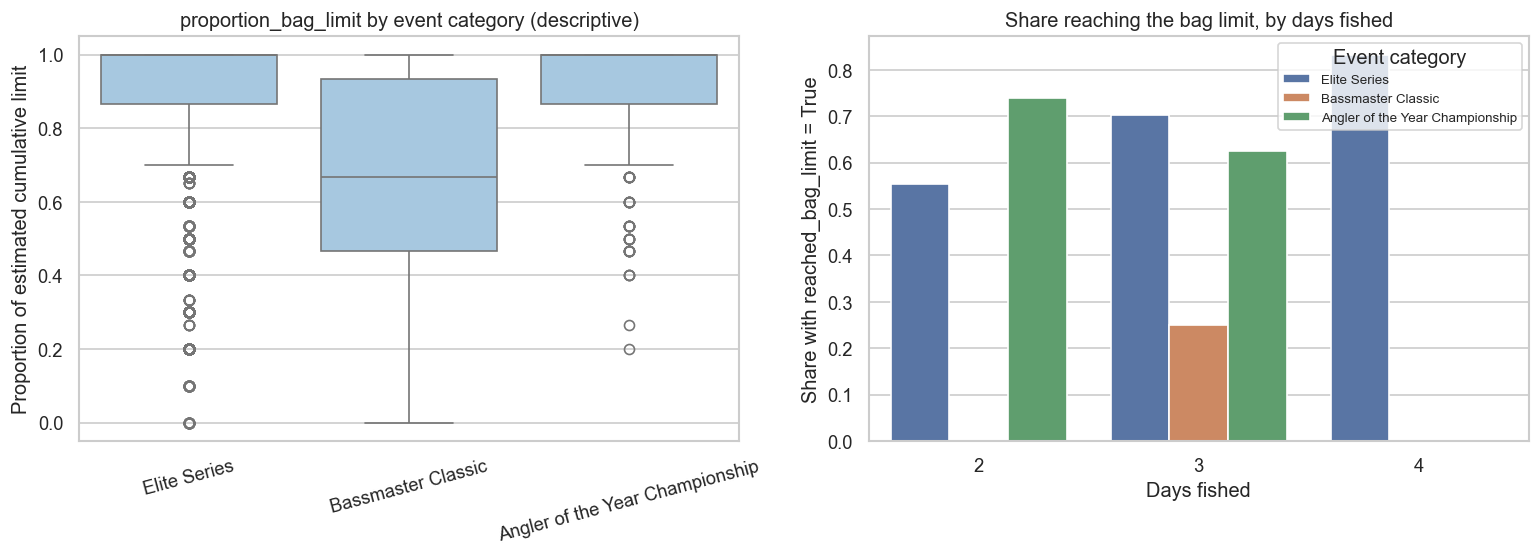

In [114]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(
    data=limit_rows, x="Event_Name", y="proportion_bag_limit",
    order=event_name_order, color="#9ecae9", ax=axes[0]
)
axes[0].set_title("proportion_bag_limit by event category (descriptive)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Proportion of estimated cumulative limit")
axes[0].tick_params(axis="x", rotation=15)

reach_by_days = (
    limit_rows.groupby(["Event_Name", "days_fished"], observed=True)["reached_bag_limit"]
    .mean().rename("Share_Reaching_Limit").reset_index()
)
sns.barplot(
    data=reach_by_days, x="days_fished", y="Share_Reaching_Limit",
    hue="Event_Name", hue_order=event_name_order, errorbar=None, ax=axes[1]
)
axes[1].set_title("Share reaching the bag limit, by days fished")
axes[1].set_xlabel("Days fished")
axes[1].set_ylabel("Share with reached_bag_limit = True")
axes[1].legend(title="Event category", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation.** These are descriptive summaries of estimated limit completion. Event categories differ in format and field size, anglers within an event are dependent, and the denominator is reconstructed rather than observed, so no inferential claim is made from these figures.

# 5. Tournament Format and Advancement Structure

## 5.1 Five-fish daily limit and estimated event duration

Bassmaster tournaments use a five-fish daily limit and progressive field cuts, so cumulative `Fish_Caught` is bounded by the number of days an angler fished: up to 10 fish after two days, 15 after three, and 20 after four. The source data have no official event-duration variable. In RStudio, the **estimated event duration** (`event_days`) was derived from the winner’s cumulative fish count (1–5 fish: one day; 6–10: two; 11–15: three; 16–20: four), with `event_bag_limit = event_days * 5`. These are reconstructed values, not directly observed records.

## 5.2 Event-specific advancement rules used in the reconstruction

- **Elite Series, four-day events through 2019:** full field on Days 1–2; the top 50 plus ties at the cut on Day 3; the **top 12** on Day 4.
- **Elite Series, four-day events beginning in 2020:** full field on Days 1–2; the top 50 plus ties on Day 3; the **top 10** on Day 4.
- **Weather-shortened three-day Elite events:** full field on Days 1–2; the top 50 plus possible ties on Day 3.
- **One- or two-day shortened Elite events:** all participants receive the completed event duration.
- **Bassmaster Classic and Angler of the Year Championship:** the full (limited) field is treated as eligible for every completed day, so `days_fished = event_days`.

## 5.3 Corrections applied before export

Final place alone is insufficient because ties at the Day 2 cut can send more than 50 anglers to Day 3. Two corrections were applied:

1. **Catch-based minimum-day correction:** more than 10 cumulative fish proves at least three days, and more than 15 proves four. `initial_days_fished` is the maximum of `rule_based_days` and `minimum_days_from_fish`.
2. **Ranking-consistency correction:** within a tournament, if a lower-finishing angler’s catch proves a later round was reached, all higher-finishing anglers receive at least the same number of days. The result is `days_fished`, with `bag_limit = days_fished * 5`.

`days_fished` and `bag_limit` are therefore an **estimated angler-specific cumulative bag limit**, not an official limit. A tied advancer outside the top 50 with 10 or fewer cumulative fish may remain assigned two days.

In [115]:
event_structure = (
    analysis_rows.sort_values(["Event_Key", "Place", "Angler_Name"])
    .groupby("Event_Key", observed=True)
    .agg(
        Season_Year=("Season_Year", "first"),
        Tournament_ID=("Tournament_ID", "first"),
        Event_Name=("Event_Name", "first"),
        Waterbody=("Waterbody", "first"),
        Allowed_FFS=("Allowed_FFS", "first"),
        Clean_Angler_Records=("Player_ID", "size"),
        Winner_Fish_Caught=("winner_fish_caught", "first"),
        estimated_event_days=("event_days", "first"),
        estimated_event_bag_limit=("event_bag_limit", "first"),
        Maximum_Fish_Caught=("Fish_Caught", "max"),
        Minimum_Days_Fished=("days_fished", "min"),
        Maximum_Days_Fished=("days_fished", "max"),
        Anglers_Below_Event_Days=("days_fished", lambda x: int(x.lt(x.max()).sum())),
    )
    .reset_index()
)
event_structure["Angler_Records"] = event_structure["Event_Key"].map(
    df.groupby("Event_Key", observed=True).size()
)
event_structure["Is_Bassmaster_Classic"] = event_structure["Event_Name"].eq("Bassmaster Classic")
event_structure["Is_Elite_Series"] = event_structure["Event_Name"].eq("Elite Series")

for column in ["event_days", "event_bag_limit", "winner_fish_caught"]:
    assert analysis_rows.groupby("Event_Key", observed=True)[column].nunique().max() == 1, column
assert event_structure["Event_Key"].is_unique
print("Unique event-level records:", event_structure["Event_Key"].nunique())
display(
    event_structure.groupby(["Event_Name", "estimated_event_days"], dropna=False)
    .size().rename("Tournaments").to_frame()
)

Unique event-level records: 150


Tournaments
Event_Name                      estimated_event_days             
Angler of the Year Championship 2                               1
                                3                               5
Bassmaster Classic              3                              13
Elite Series                    3                               4
                                4                             127

## 5.4 How much the corrections changed the day assignments

The table counts angler rows whose estimated days exceed the place-based rule (catch-based correction) and rows raised further by the ranking-consistency correction. Estimated days are never presented as observed.

In [116]:
days_adjustments = analysis_rows.assign(
    Raised_By_Catch=analysis_rows["initial_days_fished"].gt(analysis_rows["rule_based_days"]),
    Raised_By_Ranking=analysis_rows["days_fished"].gt(analysis_rows["initial_days_fished"]),
)
adjustment_summary = (
    days_adjustments.groupby("Event_Name", observed=True)
    .agg(
        Angler_Rows=("Event_Key", "size"),
        Raised_By_Catch=("Raised_By_Catch", "sum"),
        Raised_By_Ranking=("Raised_By_Ranking", "sum"),
        Events_With_Any_Adjustment=(
            "Event_Key",
            lambda x: x[days_adjustments.loc[x.index, ["Raised_By_Catch", "Raised_By_Ranking"]].any(axis=1)].nunique(),
        ),
    )
)
display(adjustment_summary)
display(
    pd.crosstab(analysis_rows["Event_Name"], analysis_rows["days_fished"], margins=True)
    .rename_axis(index="Event_Name", columns="Estimated days fished")
)

,Angler_Rows,Raised_By_Catch,Raised_By_Ranking,Events_With_Any_Adjustment
Event_Name,,,,
Angler of the Year Championship,300,0,0,0
Bassmaster Classic,705,0,0,0
Elite Series,12962,17,20,14


Estimated days fished,2,3,4,All
Event_Name,,,,
Angler of the Year Championship,50,250,0,300
Bassmaster Classic,0,705,0,705
Elite Series,6368,5193,1401,12962
All,6418,6148,1401,13967


## 5.5 Event-structure audit

The audit table lists the imported event-level reconstruction for each tournament. Classic and Angler of the Year events are identified explicitly. All durations and limits are estimates.

In [117]:
# Standardize the ambiguous "allowed" category
df["Allowed_FFS"] = df["Allowed_FFS"].replace(
    {"allowed": "Yes (Unrestricted)"}
)

# Update the event-level table if it already exists
if "event_structure" in globals():
    event_structure["Allowed_FFS"] = (
        event_structure["Allowed_FFS"]
        .replace({"allowed": "Yes (Unrestricted)"})
    )

audit_columns = [
    "Event_Key", "Season_Year", "Tournament_ID", "Event_Name", "Waterbody",
    "Allowed_FFS", "Angler_Records", "Clean_Angler_Records", "Winner_Fish_Caught",
    "estimated_event_days", "estimated_event_bag_limit", "Maximum_Fish_Caught",
    "Minimum_Days_Fished", "Maximum_Days_Fished", "Anglers_Below_Event_Days",
    "Is_Bassmaster_Classic", "Is_Elite_Series",
]
display(event_structure[audit_columns].sort_values(["Season_Year", "Tournament_ID"]).reset_index(drop=True))
display(
    event_structure.groupby(["Event_Name", "Allowed_FFS"], observed=True)
    .agg(
        Tournaments=("Event_Key", "nunique"),
        Median_Estimated_Days=("estimated_event_days", "median"),
        Median_Field_Size=("Angler_Records", "median"),
    )
)

,Event_Key,Season_Year,Tournament_ID,Event_Name,Waterbody,Allowed_FFS,Angler_Records,Clean_Angler_Records,Winner_Fish_Caught,estimated_event_days,estimated_event_bag_limit,Maximum_Fish_Caught,Minimum_Days_Fished,Maximum_Days_Fished,Anglers_Below_Event_Days,Is_Bassmaster_Classic,Is_Elite_Series
0,2012_1,2012,1,Bassmaster Classic,Red River,No FFS Existed,49,49,15,3,15,15,3,3,0,True,False
1,2012_2,2012,2,Elite Series,St. Johns River,No FFS Existed,99,99,20,4,20,20,2,4,87,False,True
2,2012_3,2012,3,Elite Series,Lake Okeechobee,No FFS Existed,99,99,20,4,20,20,2,4,87,False,True
3,2012_4,2012,4,Elite Series,Bull Shoals Lake,No FFS Existed,99,99,20,4,20,20,2,4,87,False,True
4,2012_5,2012,5,Elite Series,Douglas Lake,No FFS Existed,99,99,20,4,20,20,2,4,87,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145,2026_6,2026,6,Elite Series,Lake Murray,Yes (Restricted),99,99,20,4,20,20,2,4,89,False,True
146,2026_7,2026,7,Elite Series,Santee Cooper Lakes,No,99,99,20,4,20,20,2,4,89,False,True
147,2026_8,2026,8,Elite Series,Pasquotank River / Albemarle Sound,Yes (Restricted),98,98,19,4,20,20,2,4,88,False,True
148,2026_9,2026,9,Elite Series,Lake Champlain,No,98,98,20,4,20,20,2,4,88,False,True


Tournaments  \
Event_Name                      Allowed_FFS                       
Angler of the Year Championship Yes (Unrestricted)            3   
                                unavailable                   3   
Bassmaster Classic              No FFS Existed                3   
                                Yes (Unrestricted)            7   
                                Yes (Restricted)              2   
                                unavailable                   1   
Elite Series                    No FFS Existed               19   
                                Yes (Unrestricted)           84   
                                Yes (Restricted)             14   
                                No                            4   
                                unavailable                  10   

                                                    Median_Estimated_Days  \
Event_Name                      Allowed_FFS                                 
Angler of the Year Championship Yes (Unrestricted)                    3.0   
                                unavailable                           3.0   
Bassmaster Classic              No FFS Existed                        3.0   
                                Yes (Unrestricted)                    3.0   
                                Yes (Restricted)                      3.0   
                                unavailable                           3.0   
Elite Series                    No FFS Existed                        4.0   
                                Yes (Unrestricted)                    4.0   
                                Yes (Restricted)                      4.0   
                                No                                    4.0   
                                unavailable                           4.0   

                                                    Median_Field_Size  
Event_Name                      Allowed_FFS                            
Angler of the Year Championship Yes (Unrestricted)               50.0  
                                unavailable                      50.0  
Bassmaster Classic              No FFS Existed                   53.0  
                                Yes (Unrestricted)               55.0  
                                Yes (Restricted)                 57.0  
                                unavailable                      52.0  
Elite Series                    No FFS Existed                   99.0  
                                Yes (Unrestricted)              102.0  
                                Yes (Restricted)                101.0  
                                No                              100.0  
                                unavailable                     108.0

## 5.6 Final choice of defensible outcomes

The primary response remains **tournament median average fish weight** among positive-catch anglers. It describes fish size, not an individual treatment response, and can still reflect high-grading, event duration, fishery composition, and field selection.

The secondary outcome is `proportion_bag_limit`, the share of an *estimated* angler-specific cumulative limit completed. Tournament-level summaries (median, mean, interquartile range, and the proportion of anglers reaching their estimated limit) are built in Section 6 and used for all inferential comparisons. Other event summaries (field size, cumulative fish count and weight, zero-catch proportion) remain descriptive.

# 6. Tournament-Level Analytical Dataset

## 6.1 Why tournament is the primary independent unit

Anglers in an event share the waterbody, weather, schedule, rules, and event conditions, while individual anglers recur across events. Treating all angler rows as independent would overstate the amount of independent information. Every primary comparison below uses one observation per `Event_Key`.


## 6.2 Tournament-level outcome definitions

The table is built once, then reused for comparisons, time-series summaries, clustering, and anomaly detection. `Tournament_ID` is never used alone as a key.

In [118]:
def event_weight_spread(series):
    values = series.dropna()
    return values.quantile(0.75) - values.quantile(0.25) if len(values) else np.nan

def event_q75(series):
    values = series.dropna()
    return values.quantile(0.75) if len(values) else np.nan

event_features = analysis_rows.groupby("Event_Key", observed=True).agg(
    Season_Year=("Season_Year", "first"),
    Tournament_ID=("Tournament_ID", "first"),
    Event_Name=("Event_Name", "first"),
    Waterbody=("Waterbody", "first"),
    Allowed_FFS=("Allowed_FFS", "first"),
    FFS_Simple=("FFS_Simple", "first"),
    Month=("Month", "first"),
    Angler_Records=("Player_ID", "size"),
    Median_Avg_Fish_Weight=("Avg_Fish_Weight", "median"),
    Mean_Avg_Fish_Weight=("Avg_Fish_Weight", "mean"),
    Median_Weight_Lbs=("Weight_Lbs_Calculated", "median"),
    Upper_Quartile_Weight_Lbs=("Weight_Lbs_Calculated", event_q75),
    Weight_IQR_Lbs=("Weight_Lbs_Calculated", event_weight_spread),
    Median_Fish_Caught=("Fish_Caught", "median"),
    Proportion_Zero_Fish=("Fish_Caught", lambda x: x.eq(0).mean()),
    Proportion_Reaching_10_Fish=("Fish_Caught", lambda x: x.ge(10).mean()),
    Winner_Weight_Lbs=("Weight_Lbs_Calculated", lambda x: x.loc[analysis_rows.loc[x.index, "Place"].eq(1)].max()),
)
event_features = event_features.reset_index()
tournament_df = event_features.copy()

assert tournament_df["Event_Key"].is_unique
print("Tournament-level analytical table:", tournament_df.shape)
print("Unique Event_Key check:", tournament_df["Event_Key"].is_unique)

Tournament-level analytical table: (150, 18)
Unique Event_Key check: True


## 6.3 Tournament-level summaries of `proportion_bag_limit`

Before any bootstrap, time-series, anomaly, or FFS comparison, the angler-level reconstructed outcome is aggregated to **one row per `Event_Key`**. `proportion_bag_limit` is a proportion (0–1); `percent_bag_limit` is not used in inference. Any bootstrap involving these outcomes resamples rows of `tournament_limit_summary`, never angler rows.

In [119]:
tournament_limit_summary = (
    analysis_rows.groupby("Event_Key", observed=True)
    .agg(
        Season_Year=("Season_Year", "first"),
        Tournament_ID=("Tournament_ID", "first"),
        Event_Name=("Event_Name", "first"),
        Waterbody=("Waterbody", "first"),
        Allowed_FFS=("Allowed_FFS", "first"),
        estimated_event_days=("event_days", "first"),
        number_of_anglers=("Angler_Name", "size"),
        median_proportion_limit=("proportion_bag_limit", "median"),
        mean_proportion_limit=("proportion_bag_limit", "mean"),
        iqr_proportion_limit=("proportion_bag_limit", event_weight_spread),
        proportion_reaching_limit=("reached_bag_limit", "mean"),
    )
    .reset_index()
)
tournament_limit_summary["proportion_reaching_limit"] = tournament_limit_summary[
    "proportion_reaching_limit"
].astype(float)
assert tournament_limit_summary["Event_Key"].is_unique

tournament_df = tournament_df.merge(
    tournament_limit_summary[
        ["Event_Key", "estimated_event_days", "median_proportion_limit",
         "mean_proportion_limit", "iqr_proportion_limit", "proportion_reaching_limit"]
    ],
    on="Event_Key", how="left", validate="one_to_one",
)
print("tournament_limit_summary:", tournament_limit_summary.shape)
display(tournament_limit_summary.drop(columns=["Tournament_ID"]).describe().T.round(3))

tournament_limit_summary: (150, 12)


,count,mean,std,min,25%,50%,75%,max
Season_Year,150.0,2019.087,4.258,2012.000,2016.000,2019.000,2023.000,2026.0
estimated_event_days,150.0,3.840,0.386,2.000,4.000,4.000,4.000,4.0
number_of_anglers,150.0,93.113,18.559,49.000,87.250,100.000,107.000,113.0
median_proportion_limit,150.0,0.913,0.149,0.400,0.900,1.000,1.000,1.0
mean_proportion_limit,150.0,0.873,0.121,0.441,0.823,0.919,0.962,1.0
iqr_proportion_limit,150.0,0.156,0.164,0.000,0.000,0.100,0.300,0.6
proportion_reaching_limit,150.0,0.602,0.272,0.018,0.405,0.652,0.820,1.0


## 6.4 Tournament-level summary table

The table below gives the descriptive event-level feature profile. Limit-based features use the estimated angler-specific cumulative limit and are not observed official limits.

In [120]:
data_dictionary = pd.DataFrame(
    [
        ("Event_Key", "Unique event key, Season_Year + Tournament_ID", "Identifier"),
        ("Season_Year", "Season of the event", "Year"),
        ("Event_Name", "Elite Series, Classic, or AOY event category", "Category"),
        ("Waterbody", "Standardized fishery name as supplied", "Category"),
        ("Allowed_FFS", "Observed event-rule label; not actual angler use", "Category"),
        ("Month", "Event month as supplied; missing for some events", "Descriptor"),
        ("Angler_Records", "Number of clean angler records in the event", "Count"),
        ("Median_Avg_Fish_Weight", "Median pounds per fish among anglers with positive catch", "Primary outcome"),
        ("Mean_Avg_Fish_Weight", "Mean pounds per fish among anglers with positive catch", "Sensitivity outcome"),
        ("Median_Weight_Lbs", "Median cumulative event weight across the field", "Descriptive; field-cut sensitive"),
        ("Upper_Quartile_Weight_Lbs", "75th percentile cumulative event weight", "Descriptive; field-cut sensitive"),
        ("Weight_IQR_Lbs", "75th minus 25th percentile cumulative event weight", "Descriptive; field-cut sensitive"),
        ("Median_Fish_Caught", "Median cumulative fish count", "Descriptive; field-cut sensitive"),
        ("Proportion_Zero_Fish", "Share of clean field records with zero fish", "Proportion"),
        ("Proportion_Reaching_10_Fish", "Share with at least 10 cumulative fish", "Proportion"),
        ("Winner_Weight_Lbs", "Winning cumulative weight", "Descriptive; exposure-sensitive"),
        ("estimated_event_days", "Estimated event duration from the winner's cumulative fish count (RStudio)", "Reconstructed"),
        ("median_proportion_limit", "Median proportion_bag_limit across the field", "Secondary outcome; estimated denominator"),
        ("mean_proportion_limit", "Mean proportion_bag_limit across the field", "Sensitivity outcome"),
        ("iqr_proportion_limit", "Interquartile range of proportion_bag_limit", "Descriptive spread"),
        ("proportion_reaching_limit", "Share of anglers with reached_bag_limit = True", "Secondary outcome; estimated denominator"),
        ("Anomaly_03", "Isolation Forest flag using 3% contamination", "Review signal only"),
        ("Anomaly_05", "Isolation Forest flag using 5% contamination", "Review signal only"),
    ],
    columns=["Feature", "Definition", "Role / limitation"],
)
display(data_dictionary)
display(tournament_df.describe(include="number").T.round(3))

,Feature,Definition,Role / limitation
0,Event_Key,"Unique event key, Season_Year + Tournament_ID",Identifier
1,Season_Year,Season of the event,Year
2,Event_Name,"Elite Series, Classic, or AOY event category",Category
3,Waterbody,Standardized fishery name as supplied,Category
4,Allowed_FFS,Observed event-rule label; not actual angler use,Category
5,Month,Event month as supplied; missing for some events,Descriptor
6,Angler_Records,Number of clean angler records in the event,Count
7,Median_Avg_Fish_Weight,Median pounds per fish among anglers with posi...,Primary outcome
8,Mean_Avg_Fish_Weight,Mean pounds per fish among anglers with positi...,Sensitivity outcome
9,Median_Weight_Lbs,Median cumulative event weight across the field,Descriptive; field-cut sensitive


,count,mean,std,min,25%,50%,75%,max
Season_Year,150.0,2019.087,4.258,2012.000,2016.000,2019.000,2023.000,2026.000
Tournament_ID,150.0,5.533,2.932,1.000,3.000,5.500,8.000,11.000
Angler_Records,150.0,93.113,18.559,49.000,87.250,100.000,107.000,113.000
Median_Avg_Fish_Weight,150.0,2.820,0.611,1.398,2.417,2.745,3.230,4.614
Mean_Avg_Fish_Weight,150.0,2.838,0.598,1.435,2.435,2.742,3.261,4.552
Median_Weight_Lbs,150.0,28.427,9.113,10.438,22.766,27.328,32.844,60.312
Upper_Quartile_Weight_Lbs,150.0,44.799,10.923,18.875,38.102,43.562,52.898,76.344
Weight_IQR_Lbs,150.0,22.001,5.382,8.297,18.691,22.031,25.586,40.750
Median_Fish_Caught,150.0,10.227,1.615,5.000,10.000,10.000,10.000,15.000
Proportion_Zero_Fish,150.0,0.003,0.007,0.000,0.000,0.000,0.000,0.036


## 6.4 Coverage across FFS categories, years, and waterbodies

For primary comparisons, the main event type is **Elite Series only**. Bassmaster Classic and Angler of the Year Championship are kept in the analytical table and used in an all-event-type sensitivity summary, but not pooled into the primary result because their formats and schedules may differ.

The main clear-label contrast is `No FFS Existed` versus `Yes (Unrestricted)`. The labels `No`, `Yes (Restricted)`, `allowed`, and `unavailable` remain distinct. The `allowed` and `unavailable` labels are unresolved in this compilation and excluded from the primary comparison. This conservative comparison still contrasts different calendar periods and is not causal.

The separate `FFS_Simple` table is descriptive only: it combines unrestricted, restricted, and unresolved `allowed` labels as `Yes`, and combines `No` and `No FFS Existed` as `No`. `unavailable` and unknown labels remain separate. This simplification is not used in the primary bootstrap or interpreted as actual sonar use.


In [121]:
primary_events = tournament_df.loc[
    tournament_df["Event_Name"].eq("Elite Series")
].copy()
PRIMARY_LABELS = ["No FFS Existed", "No", "Yes (Unrestricted)", "Yes (Restricted)", "allowed"]
primary_comparison = primary_events.loc[
    primary_events["Allowed_FFS"].astype(str).isin(PRIMARY_LABELS)
    & primary_events["Median_Avg_Fish_Weight"].notna()
].copy()

row_status_counts = (
    analysis_rows["Allowed_FFS"].astype(str).value_counts()
    .rename("Angler rows")
)
tournament_status_counts = (
    tournament_df["Allowed_FFS"].astype(str).value_counts()
    .rename("Unique tournaments")
)
status_counts = pd.concat([row_status_counts, tournament_status_counts], axis=1).fillna(0).astype(int)
display(status_counts.reindex(ffs_categories))
print("Primary event type: Elite Series")
print("Elite tournaments in full analytical table:", len(primary_events))
print("Primary comparison tournaments:", len(primary_comparison))
print("Primary labels:", primary_comparison["Allowed_FFS"].value_counts().to_dict())


,Angler rows,Unique tournaments
Allowed_FFS,,
No FFS Existed,2080,22
Yes (Unrestricted),8687,94
Yes (Restricted),1530,16
No,399,4
unavailable,1271,14


Primary event type: Elite Series
Elite tournaments in full analytical table: 131
Primary comparison tournaments: 121
Primary labels: {'Yes (Unrestricted)': 84, 'No FFS Existed': 19, 'Yes (Restricted)': 14, 'No': 4, 'unavailable': 0}


In [122]:
pd.crosstab(
    df["Allowed_FFS"],
    df["FFS_Simple"],
    margins=True
)

FFS_Simple,No,Yes,Unavailable,All
Allowed_FFS,,,,
No FFS Existed,2080,0,0,2080
Yes (Unrestricted),0,8688,0,8688
Yes (Restricted),0,1530,0,1530
No,399,0,0,399
unavailable,0,0,1271,1271
All,2479,10218,1271,13968


In [123]:
ffs_simple_summary = (
    df.groupby("FFS_Simple")
      .agg(
          Angler_rows=("FFS_Simple", "size"),
          Unique_tournaments=("Event_Key", "nunique")
      )
      .reindex(["Unavailable", "No", "Yes"], fill_value=0)
)

ffs_simple_summary

/var/folders/5l/xbt3m1s500g44pgjwvtjq7xh0000gn/T/ipykernel_57555/145386803.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("FFS_Simple")


,Angler_rows,Unique_tournaments
FFS_Simple,,
Unavailable,1271,14
No,2479,26
Yes,10218,110


In [124]:
simple_elite_events = tournament_df.loc[
    tournament_df["Event_Name"].eq("Elite Series")
].copy()
SIMPLE_LABELS = ["No", "Yes"]
simple_comparison = simple_elite_events.loc[
    simple_elite_events["FFS_Simple"].isin(SIMPLE_LABELS)
    & simple_elite_events["Median_Avg_Fish_Weight"].notna()
].copy()

simple_row_status_counts = (
    analysis_rows["FFS_Simple"].astype(str).value_counts()
    .rename("Angler rows")
)
simple_tournament_status_counts = (
    tournament_df["FFS_Simple"].astype(str).value_counts()
    .rename("Unique tournaments")
)
simple_status_counts = pd.concat([simple_row_status_counts, simple_tournament_status_counts], axis=1).fillna(0).astype(int)
display(simple_status_counts.reindex(["No", "Yes", "Unavailable"], fill_value=0))
print("Simplified-label event type: Elite Series")
print("Elite tournaments in full analytical table:", len(simple_elite_events))
print("Simplified-label comparison tournaments:", len(simple_comparison))
print("Simplified labels:", simple_comparison["FFS_Simple"].value_counts().to_dict())

,Angler rows,Unique tournaments
FFS_Simple,,
No,2479,26
Yes,10217,110
Unavailable,1271,14


Simplified-label event type: Elite Series
Elite tournaments in full analytical table: 131
Simplified-label comparison tournaments: 121
Simplified labels: {'Yes': 98, 'No': 23, 'Unavailable': 0}


# 7. Resampling-Based Comparisons

## 7.1 Comparison definitions

The main comparison is the difference in tournament medians, **`Yes (Unrestricted)` minus `No FFS Existed`**, for the tournament median average-fish-weight outcome. Each event contributes one observation. The primary contrast is supported by more events than the restricted-era groups, but its categories occupy different calendar periods and fishery schedules.

For each comparison the notebook reports event counts, represented years, waterbodies, event types, estimated event duration composition, and waterbody overlap before interpreting the outcome.

In [125]:
# PRIMARY_LABELS = ["Unavailable", "No", "Yes"]

# primary_comparison = (
#     tournament_df.loc[
#         tournament_df["Event_Name"].eq("Elite Series")
#         & tournament_df["FFS_Simple"].isin(PRIMARY_LABELS)
#     ]
#     .copy()
# )

def comparison_context(data, labels):
    rows = []
    for label in labels:
        subset = data.loc[data["Allowed_FFS"].astype(str).eq(label)]
        rows.append(
            {
                "FFS label": label,
                "Tournaments": subset["Event_Key"].nunique(),
                "Years": ", ".join(map(str, sorted(subset["Season_Year"].unique()))),
                "Waterbodies": subset["Waterbody"].nunique(),
                "Event types": subset["Event_Name"].value_counts().to_dict(),
                "Estimated event days": subset["estimated_event_days"].value_counts(dropna=False).to_dict(),
                "Median outcome (lb/fish)": subset["Median_Avg_Fish_Weight"].median(),
                "Mean outcome (lb/fish)": subset["Median_Avg_Fish_Weight"].mean(),
            }
        )
    water_sets = [
        set(data.loc[data["Allowed_FFS"].astype(str).eq(label), "Waterbody"])
        for label in labels
    ]
    print("Waterbodies represented under every compared label:", len(set.intersection(*water_sets)))
    year_sets = [
        set(data.loc[data["Allowed_FFS"].astype(str).eq(label), "Season_Year"])
        for label in labels
    ]
    print("Years represented under every compared label:", len(set.intersection(*year_sets)))
    return pd.DataFrame(rows)

display(comparison_context(primary_comparison, PRIMARY_LABELS))

Waterbodies represented under every compared label: 0
Years represented under every compared label: 0


,FFS label,Tournaments,Years,Waterbodies,Event types,Estimated event days,Median outcome (lb/fish),Mean outcome (lb/fish)
0,No FFS Existed,19,"2012, 2013, 2014",17,{'Elite Series': 19},{4: 19},2.513542,2.600279
1,No,4,2026,4,{'Elite Series': 4},{4: 4},3.307292,3.096875
2,Yes (Unrestricted),84,"2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022...",38,{'Elite Series': 84},"{4: 80, 3: 4}",2.775240,2.804080
3,Yes (Restricted),14,"2025, 2026",14,{'Elite Series': 14},{4: 14},2.608333,2.866378
4,allowed,0,,0,{},{},NaN,NaN


## 7.2 Bootstrap confidence intervals

The percentile interval resamples **tournaments**, not angler rows. It is an interval for the observed difference under event-level resampling; it does not have a 95% probability of containing a fixed parameter. Repeated waterbodies and time confounding remain limitations.

,Primary tournament bootstrap
label_a,No FFS Existed
label_b,Yes (Unrestricted)
n_a,19
n_b,84
observed_median_difference,0.261699
ci_low,0.024475
ci_high,0.476773
observed_mean_difference,0.2038
bootstrap_draws,5000


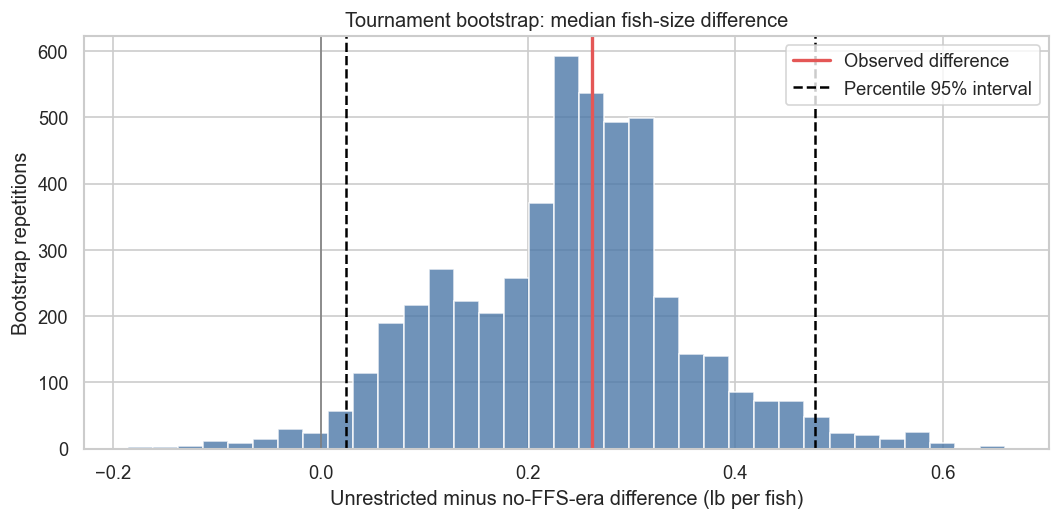

In [126]:
def bootstrap_difference(data, label_a, label_b, outcome, reps=BOOTSTRAP_REPS, seed=RANDOM_SEED):
    a = data.loc[data["Allowed_FFS"].astype(str).eq(label_a), outcome].dropna().to_numpy()
    b = data.loc[data["Allowed_FFS"].astype(str).eq(label_b), outcome].dropna().to_numpy()
    if min(len(a), len(b)) < 2:
        return {
            "label_a": label_a, "label_b": label_b, "n_a": len(a), "n_b": len(b),
            "observed_median_difference": np.nan, "ci_low": np.nan, "ci_high": np.nan,
            "observed_mean_difference": np.nan, "bootstrap_draws": 0,
        }
    local_rng = np.random.default_rng(seed)
    observed = np.median(b) - np.median(a)
    observed_mean = np.mean(b) - np.mean(a)
    draws = np.empty(reps)
    for i in range(reps):
        boot_a = local_rng.choice(a, size=len(a), replace=True)
        boot_b = local_rng.choice(b, size=len(b), replace=True)
        draws[i] = np.median(boot_b) - np.median(boot_a)
    low, high = np.quantile(draws, [0.025, 0.975])
    return {
        "label_a": label_a, "label_b": label_b, "n_a": len(a), "n_b": len(b),
        "observed_median_difference": observed, "ci_low": low, "ci_high": high,
        "observed_mean_difference": observed_mean, "bootstrap_draws": reps,
        "draws": draws,
    }

primary_bootstrap = bootstrap_difference(
    primary_comparison, "No FFS Existed", "Yes (Unrestricted)",
    "Median_Avg_Fish_Weight",
)
primary_bootstrap_summary = {
    key: value for key, value in primary_bootstrap.items() if key != "draws"
}
display(pd.Series(primary_bootstrap_summary, name="Primary tournament bootstrap").to_frame())

plt.figure(figsize=(9, 4.5))
plt.hist(primary_bootstrap["draws"], bins=35, color="#4C78A8", alpha=0.8)
plt.axvline(primary_bootstrap["observed_median_difference"], color="#E45756", lw=2, label="Observed difference")
plt.axvline(primary_bootstrap["ci_low"], color="black", ls="--", label="Percentile 95% interval")
plt.axvline(primary_bootstrap["ci_high"], color="black", ls="--")
plt.axvline(0, color="gray", lw=1)
plt.title("Tournament bootstrap: median fish-size difference")
plt.xlabel("Unrestricted minus no-FFS-era difference (lb per fish)")
plt.ylabel("Bootstrap repetitions")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation.** The displayed point estimate and percentile interval quantify event-level sampling variability for the selected contrast. Because FFS labels are separated in calendar time and reflect event scheduling, the interval does not remove those differences or identify a causal sonar effect.

## 7.3 Restricted permutation tests

The proposed null is: **within comparable tournament strata, the distribution of the outcome does not depend on the FFS rule label**. Permuting labels across years and fisheries would not represent a credible null here.

The pre-specified strata are event type, waterbody, estimated event duration, and a three-season calendar block. Labels are exchangeable only within strata containing both primary labels. If no such strata exist, the test is not run and that lack of overlap is reported. Even a valid restricted p-value would measure how unusual the statistic is under this specified label-exchangeability null; it would not be the probability the null is true or evidence of causation.

To avoid a test dominated by a handful of repeated fisheries, execution also requires at least five mixed-label strata and 20 tournaments across those strata. These are minimum diagnostics for this analysis, not universal thresholds.

In [127]:
def restricted_permutation_test(
    data, labels, outcome, strata_columns, reps=PERMUTATION_REPS, seed=RANDOM_SEED
):
    subset = data.loc[
        data["Allowed_FFS"].astype(str).isin(labels)
        & data[outcome].notna()
    ].copy()
    subset["_label"] = subset["Allowed_FFS"].astype(str)
    grouped = list(subset.groupby(strata_columns, dropna=False, observed=True))
    mixed_groups = [
        group.copy() for _, group in grouped
        if group["_label"].nunique() > 1
    ]
    if not mixed_groups:
        return {
            "ran": False,
            "reason": "No pre-specified stratum contained both labels; exchangeability is unsupported.",
            "mixed_strata": 0,
            "mixed_events": 0,
            "permutation_statistics": np.array([]),
        }
    mixed_event_count = sum(len(group) for group in mixed_groups)
    if len(mixed_groups) < 5 or mixed_event_count < 20:
        return {
            "ran": False,
            "reason": (
                "Only a few events share FFS labels within comparable strata "
                f"({len(mixed_groups)} strata, {mixed_event_count} events); "
                "the restricted test would be dominated by sparse overlap."
            ),
            "mixed_strata": len(mixed_groups),
            "mixed_events": mixed_event_count,
            "permutation_statistics": np.array([]),
        }
    test_data = pd.concat(mixed_groups, ignore_index=True)
    observed = (
        test_data.loc[test_data["_label"].eq(labels[1]), outcome].median()
        - test_data.loc[test_data["_label"].eq(labels[0]), outcome].median()
    )
    strata_indices = [
        group.index.to_numpy()
        for _, group in test_data.groupby(strata_columns, dropna=False, observed=True)
        if group["_label"].nunique() > 1
    ]
    labels_array = test_data["_label"].to_numpy(copy=True)
    outcome_array = test_data[outcome].to_numpy()
    local_rng = np.random.default_rng(seed)
    permuted = np.empty(reps)
    for rep in range(reps):
        shuffled = labels_array.copy()
        for indices in strata_indices:
            shuffled[indices] = local_rng.permutation(shuffled[indices])
        a = outcome_array[shuffled == labels[0]]
        b = outcome_array[shuffled == labels[1]]
        permuted[rep] = np.median(b) - np.median(a)
    p_value = (1 + np.sum(np.abs(permuted) >= abs(observed))) / (reps + 1)
    return {
        "ran": True, "reason": None, "mixed_strata": len(strata_indices),
        "mixed_events": len(test_data),
        "observed": observed, "p_value": p_value,
        "permutation_statistics": permuted,
    }

primary_comparison["Year_Block"] = pd.cut(
    primary_comparison["Season_Year"],
    bins=[2011, 2014, 2017, 2020, 2023, 2026],
    labels=["2012-14", "2015-17", "2018-20", "2021-23", "2024-26"],
    include_lowest=True,
)
PERMUTATION_STRATA = [
    "Event_Name", "Waterbody", "estimated_event_days", "Year_Block"
]
permutation_result = restricted_permutation_test(
    primary_comparison, PRIMARY_LABELS, "Median_Avg_Fish_Weight",
    PERMUTATION_STRATA,
)
if permutation_result["ran"]:
    print("Restricted permutation ran within mixed strata:", permutation_result["mixed_strata"])
    print("Observed difference:", permutation_result["observed"])
    print("Permutation p-value:", permutation_result["p_value"])
    plt.figure(figsize=(9, 4.5))
    plt.hist(permutation_result["permutation_statistics"], bins=35, color="#72B7B2")
    plt.axvline(permutation_result["observed"], color="#E45756", lw=2, label="Observed statistic")
    plt.axvline(-abs(permutation_result["observed"]), color="gray", ls=":")
    plt.axvline(abs(permutation_result["observed"]), color="gray", ls=":")
    plt.title("Restricted permutation distribution")
    plt.xlabel("Median outcome difference within exchangeable strata")
    plt.ylabel("Permutations")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Restricted permutation not run:", permutation_result["reason"])
    print("Mixed-stratum diagnostics:", permutation_result["mixed_strata"], "strata and", permutation_result.get("mixed_events", 0), "events.")

Restricted permutation not run: Only a few events share FFS labels within comparable strata (5 strata, 10 events); the restricted test would be dominated by sparse overlap.
Mixed-stratum diagnostics: 5 strata and 10 events.


**Interpretation.** A permutation p-value is reported only if the stated restricted exchangeability condition is met. If not, the absence of a test is a substantive result about temporal/fishery overlap—not a reason to shuffle labels more broadly.

## 7.4 Sensitivity to outcome and event-type choices

Sensitivity analyses retain the event as the unit and use the same bootstrap interval. Results are descriptive robustness checks, not a search for significance.

In [128]:
def summarize_bootstrap_case(
    name, data, outcome="Median_Avg_Fish_Weight", labels=PRIMARY_LABELS
):
    result = bootstrap_difference(
        data, labels[0], labels[1], outcome,
        reps=BOOTSTRAP_REPS, seed=RANDOM_SEED,
    )
    values_a = data.loc[data["Allowed_FFS"].astype(str).eq(labels[0]), outcome]
    values_b = data.loc[data["Allowed_FFS"].astype(str).eq(labels[1]), outcome]
    return {
        "Sensitivity": name, "Outcome": outcome,
        "n_no_FFS": result["n_a"], "n_unrestricted": result["n_b"],
        "Median difference (lb/fish)": result["observed_median_difference"],
        "95% percentile CI low": result["ci_low"],
        "95% percentile CI high": result["ci_high"],
        "Mean difference (lb/fish)": values_b.mean() - values_a.mean()
        if len(values_a) and len(values_b) else np.nan,
    }

all_event_labels = tournament_df.loc[
    tournament_df["Allowed_FFS"].astype(str).isin(PRIMARY_LABELS)
].copy()

waterbody_counts_primary = (
    primary_comparison.groupby(["Waterbody", "Allowed_FFS"], observed=True)
    .size().unstack(fill_value=0)
)
qualifying_waterbodies = waterbody_counts_primary.index[
    waterbody_counts_primary.reindex(columns=PRIMARY_LABELS, fill_value=0).ge(2).all(axis=1)
]
repeated_fisheries = primary_comparison.loc[
    primary_comparison["Waterbody"].isin(qualifying_waterbodies)
].copy()
four_day_descriptor = primary_comparison.loc[
    primary_comparison["estimated_event_days"].eq(4)
].copy()

sensitivity_rows = [
    summarize_bootstrap_case("Primary Elite Series; median outcome", primary_comparison),
    summarize_bootstrap_case(
        "Elite Series; event mean average-fish-weight sensitivity",
        primary_comparison, outcome="Mean_Avg_Fish_Weight",
    ),
    summarize_bootstrap_case("All event types, same clear labels", all_event_labels),
    summarize_bootstrap_case("Waterbodies with >=2 events per label", repeated_fisheries),
    summarize_bootstrap_case("Estimated four-day events only", four_day_descriptor),
]
sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.round(3))
print("Unknown/unresolved FFS labels remain excluded from every comparison above; no labels were combined.")

,Sensitivity,Outcome,n_no_FFS,n_unrestricted,Median difference (lb/fish),95% percentile CI low,95% percentile CI high,Mean difference (lb/fish)
0,Primary Elite Series; median outcome,Median_Avg_Fish_Weight,19,4,0.794,-0.180,0.959,0.497
1,Elite Series; event mean average-fish-weight s...,Mean_Avg_Fish_Weight,19,4,0.779,-0.235,0.966,0.488
2,"All event types, same clear labels",Median_Avg_Fish_Weight,22,4,0.774,-0.199,0.956,0.462
3,Waterbodies with >=2 events per label,Median_Avg_Fish_Weight,0,0,NaN,NaN,NaN,NaN
4,Estimated four-day events only,Median_Avg_Fish_Weight,19,4,0.794,-0.180,0.959,0.497


Unknown/unresolved FFS labels remain excluded from every comparison above; no labels were combined.


**Sensitivity interpretation.** The primary estimate is based on 19 versus 81 Elite events. Restricting to estimated four-day events retains 19 versus 77 events, but event duration is a reconstructed estimate. Requiring at least two tournaments per label within a waterbody leaves only two fisheries (4 versus 6 events total). The mean-outcome and all-event-type estimates are shown for robustness, not as alternative primary outcomes.

## 7.5 Tournament-level bootstrap of estimated limit completion

The secondary outcomes come from `tournament_limit_summary`: each tournament contributes one value, and the bootstrap resamples **tournaments**, not angler rows. Differences are unrestricted minus no-FFS-era, in proportion units (0–1). The denominator is an estimated angler-specific cumulative limit, and the compared labels share no calendar years, so the results are associations only.

,Outcome,n_no_FFS,n_unrestricted,Median_no_FFS,Median_unrestricted,Observed median difference,Observed mean difference,95% percentile CI low,95% percentile CI high
0,median_proportion_limit,19,84,1.0000,1.0000,0.0000,-0.0109,0.0000,0.0000
1,mean_proportion_limit,19,84,0.9387,0.9210,-0.0177,-0.0098,-0.0541,0.0692
2,proportion_reaching_limit,19,84,0.6566,0.6586,0.0020,-0.0205,-0.2083,0.1563


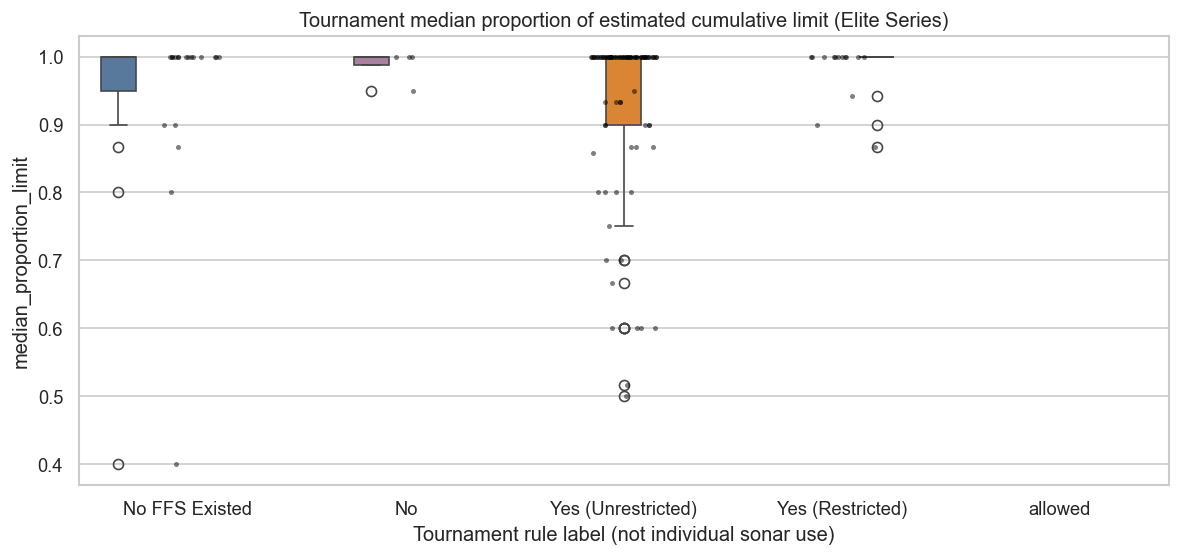

In [129]:
limit_comparison = tournament_limit_summary.loc[
    tournament_limit_summary["Event_Name"].eq("Elite Series")
    & tournament_limit_summary["Allowed_FFS"].astype(str).isin(PRIMARY_LABELS)
].copy()

limit_rows_out = []
for outcome in ["median_proportion_limit", "mean_proportion_limit", "proportion_reaching_limit"]:
    result = bootstrap_difference(
        limit_comparison, "No FFS Existed", "Yes (Unrestricted)", outcome
    )
    limit_rows_out.append(
        {
            "Outcome": outcome,
            "n_no_FFS": result["n_a"],
            "n_unrestricted": result["n_b"],
            "Median_no_FFS": limit_comparison.loc[
                limit_comparison["Allowed_FFS"].astype(str).eq("No FFS Existed"), outcome].median(),
            "Median_unrestricted": limit_comparison.loc[
                limit_comparison["Allowed_FFS"].astype(str).eq("Yes (Unrestricted)"), outcome].median(),
            "Observed median difference": result["observed_median_difference"],
            "Observed mean difference": result["observed_mean_difference"],
            "95% percentile CI low": result["ci_low"],
            "95% percentile CI high": result["ci_high"],
        }
    )
limit_bootstrap_table = pd.DataFrame(limit_rows_out)
display(limit_bootstrap_table.round(4))

plt.figure(figsize=(10, 4.8))
sns.boxplot(
    data=limit_comparison, x="Allowed_FFS", y="median_proportion_limit",
    order=PRIMARY_LABELS, hue="Allowed_FFS", hue_order=PRIMARY_LABELS,
    palette=FFS_COLORS, legend=False,
)
sns.stripplot(
    data=limit_comparison, x="Allowed_FFS", y="median_proportion_limit",
    order=PRIMARY_LABELS, color="black", alpha=0.5, size=3, jitter=0.15,
)
plt.title("Tournament median proportion of estimated cumulative limit (Elite Series)")
plt.xlabel("Tournament rule label (not individual sonar use)")
plt.ylabel("median_proportion_limit")
plt.tight_layout()
plt.show()

**Interpretation.** In this Elite Series contrast the tournament median `proportion_bag_limit` is 1.00 under both labels, so the median saturates and its interval is degenerate; the mean and the proportion of anglers reaching their estimated limit are the more informative summaries. Differences in tournament medians are small and their intervals include zero (tournament mean proportion: −0.014, interval −0.047 to +0.071; share reaching the limit: +0.016, interval −0.193 to +0.174). These estimates describe how the estimated share of eligible cumulative limits differs between tournament labels. They do not show that FFS caused anglers to catch more fish; the labels occupy separate calendar periods and the denominator is reconstructed.

# 8. Time-Series Analysis

## 8.1 Annual tournament-level trends

Annual summaries use the Elite Series tournament-level response. They report tournament counts, medians, interquartile ranges, FFS composition, and distinct waterbodies. The 2026 extract contains nine Elite tournaments, but the supplied files do not independently establish whether it represents a complete final season; 2026 is therefore shown separately and excluded from the main annual trend line.


,Tournaments,Median_Outcome,Q25,Q75,Waterbodies,FFS_n_No FFS Existed,FFS_n_Yes (Unrestricted),FFS_n_Yes (Restricted),FFS_n_No,FFS_n_unavailable
Season_Year,,,,,,,,,,
2012,8,2.498,2.448,2.578,8,8,0,0,0,0
2013,8,2.434,2.187,3.112,8,6,0,0,0,2
2014,7,2.715,2.685,2.853,7,5,0,0,0,2
2015,8,2.897,2.624,3.194,8,0,7,0,0,1
2016,9,2.431,2.300,2.724,9,0,9,0,0,0
2017,9,2.783,2.594,3.133,8,0,6,0,0,3
2018,8,2.412,2.044,2.982,8,0,6,0,0,2
2019,10,2.830,2.302,3.205,8,0,10,0,0,0
2020,10,2.912,2.565,3.207,8,0,10,0,0,0


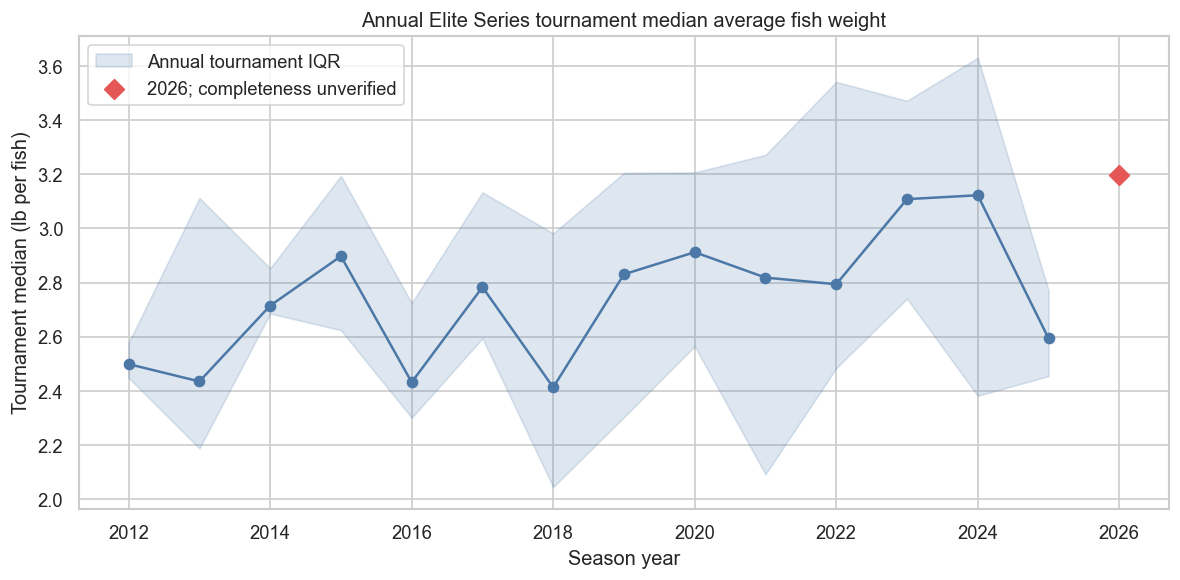

In [130]:
elite_for_time = primary_events.loc[
    primary_events["Median_Avg_Fish_Weight"].notna()
].copy()
annual_summary = (
    elite_for_time.groupby("Season_Year", observed=True)
    .agg(
        Tournaments=("Event_Key", "nunique"),
        Median_Outcome=("Median_Avg_Fish_Weight", "median"),
        Q25=("Median_Avg_Fish_Weight", lambda x: x.quantile(0.25)),
        Q75=("Median_Avg_Fish_Weight", lambda x: x.quantile(0.75)),
        Waterbodies=("Waterbody", "nunique"),
    )
)
annual_ffs_composition = pd.crosstab(
    elite_for_time["Season_Year"], elite_for_time["Allowed_FFS"].astype(str)
).reindex(columns=ffs_categories, fill_value=0)
annual_summary = annual_summary.join(
    annual_ffs_composition.add_prefix("FFS_n_")
)
display(annual_summary.round(3))

annual_complete_proxy = annual_summary.loc[annual_summary.index < 2026]
plt.figure(figsize=(10, 5))
plt.plot(annual_complete_proxy.index, annual_complete_proxy["Median_Outcome"], marker="o", color="#4C78A8")
plt.fill_between(
    annual_complete_proxy.index,
    annual_complete_proxy["Q25"],
    annual_complete_proxy["Q75"],
    color="#4C78A8", alpha=0.18, label="Annual tournament IQR"
)
if 2026 in annual_summary.index:
    plt.scatter(
        [2026], [annual_summary.loc[2026, "Median_Outcome"]],
        marker="D", s=70, color="#E45756", label="2026; completeness unverified"
    )
plt.title("Annual Elite Series tournament median average fish weight")
plt.xlabel("Season year")
plt.ylabel("Tournament median (lb per fish)")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation.** The annual medians summarize events, while the shaded IQR shows between-tournament variability. The time series is not a sonar discontinuity design: rule labels, technology, schedules, and fishery assignments all vary with year.

## 8.2 Waterbody-centered trends

Repeated visits provide a simple local-history baseline. For each waterbody, the previous observed Elite tournament median outcome is used as a one-step naive forecast for the next visit. Events are ordered by season and source tournament ID; 2026 is excluded because season completeness is not verified.


Waterbodies with repeated pre-2026 Elite visits: 28
Valid successive-visit pairs: 70
Median absolute error (lb/fish): 0.23893229166666696
Median signed error (lb/fish): 0.0676373106060606


,Successive_Visits,Median_Absolute_Error,Median_Signed_Error,Years
Allowed_FFS,,,,
No FFS Existed,2,0.223958,0.110417,"2013, 2014"
Yes (Unrestricted),55,0.225000,0.062500,"2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022..."
Yes (Restricted),8,0.186632,0.091596,2025
unavailable,5,0.258333,-0.071875,"2013, 2014, 2017, 2018"


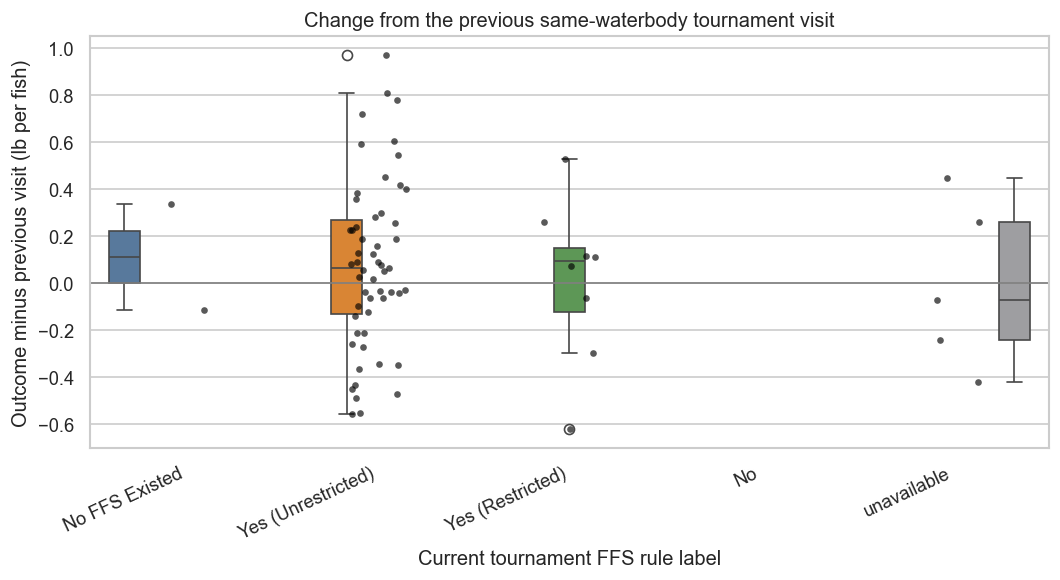

In [131]:
visits = primary_events.loc[
    primary_events["Season_Year"].lt(2026)
    & primary_events["Median_Avg_Fish_Weight"].notna()
].sort_values(["Waterbody", "Season_Year", "Tournament_ID"]).copy()
visits["Previous_Visit_Outcome"] = visits.groupby("Waterbody")["Median_Avg_Fish_Weight"].shift(1)
visits["Forecast_Error"] = visits["Median_Avg_Fish_Weight"] - visits["Previous_Visit_Outcome"]
visits["Absolute_Forecast_Error"] = visits["Forecast_Error"].abs()
valid_visit_pairs = visits.loc[visits["Previous_Visit_Outcome"].notna()].copy()

repeated_waterbody_counts = visits.groupby("Waterbody").size()
print("Waterbodies with repeated pre-2026 Elite visits:", int(repeated_waterbody_counts.ge(2).sum()))
print("Valid successive-visit pairs:", len(valid_visit_pairs))
print("Median absolute error (lb/fish):", valid_visit_pairs["Absolute_Forecast_Error"].median())
print("Median signed error (lb/fish):", valid_visit_pairs["Forecast_Error"].median())
display(
    valid_visit_pairs.groupby("Allowed_FFS", observed=True)
    .agg(
        Successive_Visits=("Event_Key", "size"),
        Median_Absolute_Error=("Absolute_Forecast_Error", "median"),
        Median_Signed_Error=("Forecast_Error", "median"),
        Years=("Season_Year", lambda x: ", ".join(map(str, sorted(x.unique())))),
    )
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=valid_visit_pairs, x="Allowed_FFS", y="Forecast_Error",
    order=ffs_categories, hue="Allowed_FFS", hue_order=ffs_categories,
    palette=FFS_COLORS, legend=False
)
sns.stripplot(
    data=valid_visit_pairs, x="Allowed_FFS", y="Forecast_Error",
    order=ffs_categories, color="black", alpha=0.65, size=4, jitter=0.15
)
plt.axhline(0, color="gray", lw=1)
plt.title("Change from the previous same-waterbody tournament visit")
plt.xlabel("Current tournament FFS rule label")
plt.ylabel("Outcome minus previous visit (lb per fish)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


**Interpretation.** Each point is a tournament following an earlier visit to the same waterbody. This naive baseline is evidence about changes from recent fishery history, not a causal model; it does not account for visit spacing, season, or environmental changes.

## 8.3 Simple time-based baseline

The previous-visit baseline is the selected course-style one-step forecast. Its absolute and signed errors are reported above overall and by current FFS rule label where pairs exist. No extrapolation beyond observed years is made.

## 8.4 Interpretation and confounding with calendar time

The known FFS labels are almost era markers in this compilation: pre-availability events are early, unrestricted events are largely middle/late, and restricted/`No` events are concentrated in the latest seasons. A same-waterbody history baseline reduces some between-fishery contrast but cannot separate rule changes from other year-specific changes.


# 9. Similarity and Clustering of Fisheries

## 9.1 Fishery feature construction

One row per Elite Series waterbody is used, requiring at least three tournaments for descriptive clustering. The cluster features describe outcome level, within-waterbody outcome spread, typical cumulative catch, zero-catch share, and field size. Tournament count and median year are shown for context but are not cluster inputs, avoiding a direct split on sample size or era. No FFS-change feature is included because it would largely encode calendar-time overlap.


In [132]:
waterbody_event_counts = primary_events.groupby("Waterbody").size()
MIN_CLUSTER_EVENTS = 3
cluster_waterbodies = waterbody_event_counts.index[waterbody_event_counts.ge(MIN_CLUSTER_EVENTS)]
cluster_source = primary_events.loc[primary_events["Waterbody"].isin(cluster_waterbodies)].copy()

cluster_features = cluster_source.groupby("Waterbody").agg(
    N_Tournaments=("Event_Key", "nunique"),
    Median_Outcome=("Median_Avg_Fish_Weight", "median"),
    IQR_Outcome=("Median_Avg_Fish_Weight", lambda x: x.quantile(.75) - x.quantile(.25)),
    Median_Cumulative_Fish=("Median_Fish_Caught", "median"),
    Median_Cumulative_Weight=("Median_Weight_Lbs", "median"),
    Median_Zero_Catch_Share=("Proportion_Zero_Fish", "median"),
    Median_Field_Size=("Angler_Records", "median"),
    Median_Year=("Season_Year", "median"),
    N_Years=("Season_Year", "nunique"),
)
cluster_features = cluster_features.reset_index().set_index("Waterbody")
cluster_input_columns = [
    "Median_Outcome", "IQR_Outcome", "Median_Cumulative_Fish",
    "Median_Cumulative_Weight", "Median_Zero_Catch_Share", "Median_Field_Size",
]
cluster_input_raw = cluster_features[cluster_input_columns].copy()
cluster_missing = cluster_input_raw.isna().sum().rename("Missing values").to_frame()
display(cluster_features)
display(cluster_missing)
print("Waterbodies with at least three Elite tournaments:", len(cluster_features))
print("Events represented in clustering:", int(cluster_features["N_Tournaments"].sum()))


,N_Tournaments,Median_Outcome,IQR_Outcome,Median_Cumulative_Fish,Median_Cumulative_Weight,Median_Zero_Catch_Share,Median_Field_Size,Median_Year,N_Years
Waterbody,,,,,,,,,
Cayuga Lake,3,3.166667,0.270833,10.0,32.562500,0.000000,106.0,2016.0,3
Lake Champlain,7,3.350000,0.182292,10.0,33.750000,0.000000,98.0,2021.0,6
Lake Fork,5,3.687500,0.431250,10.0,37.906250,0.000000,99.0,2022.0,5
Lake Guntersville,6,3.157738,0.414191,10.0,31.046875,0.000000,91.5,2019.5,5
Lake Hartwell,3,2.513194,0.270052,10.0,25.281250,0.000000,74.0,2019.0,2
Lake Murray,3,3.337500,0.203255,10.0,34.000000,0.009615,103.0,2024.0,3
Lake Okeechobee,3,2.483333,0.311806,10.0,29.375000,0.009615,104.0,2023.0,3
Lake St. Clair,5,3.562500,0.312500,10.0,35.250000,0.000000,103.0,2020.0,5
Mississippi River,7,2.513542,0.167708,10.0,26.062500,0.000000,99.0,2018.0,7


,Missing values
Median_Outcome,0
IQR_Outcome,0
Median_Cumulative_Fish,0
Median_Cumulative_Weight,0
Median_Zero_Catch_Share,0
Median_Field_Size,0


Waterbodies with at least three Elite tournaments: 14
Events represented in clustering: 75


## 9.2 Scaling and similarity

Features use different units and ranges, so the clustering matrix is standardized with `StandardScaler`. Missing cluster features are not imputed unless there are missing values; any missingness is reported first. Zero-variance features are removed and documented before distances are calculated.


In [133]:
if cluster_input_raw.isna().any().any():
    raise ValueError("Unexpected missing clustering features; resolve before fitting.")
zero_variance_features = cluster_input_raw.columns[
    cluster_input_raw.nunique(dropna=False).le(1)
].tolist()
cluster_input_raw = cluster_input_raw.drop(columns=zero_variance_features)
if zero_variance_features:
    print("Removed zero-variance cluster features:", zero_variance_features)
assert cluster_input_raw.shape[1] > 0

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_input_raw)
cluster_scaled_df = pd.DataFrame(
    cluster_scaled, index=cluster_input_raw.index, columns=cluster_input_raw.columns
)
display(cluster_input_raw.describe().T.round(3))


Removed zero-variance cluster features: ['Median_Cumulative_Fish']


,count,mean,std,min,25%,50%,75%,max
Median_Outcome,14.0,2.966,0.599,1.529,2.530,3.155,3.347,3.688
IQR_Outcome,14.0,0.314,0.133,0.168,0.240,0.290,0.346,0.684
Median_Cumulative_Weight,14.0,30.205,6.569,12.859,27.242,30.930,33.938,39.312
Median_Zero_Catch_Share,14.0,0.002,0.004,0.000,0.000,0.000,0.000,0.010
Median_Field_Size,14.0,99.000,8.304,74.000,98.250,100.500,103.000,108.000


## 9.3 Clustering

K-means solutions for k=2 through k=6 are evaluated where feasible. Silhouette scores are reported with cluster sizes; a numerical maximum is not sufficient if a cluster contains fewer than three fisheries or the profiles are not interpretable. If none meets the minimum-size rule, no cluster solution is accepted; k=2 is retained only as an exploratory diagnostic for visualization and stability checks. PCA is used only to visualize that exploratory partition.


,k,Silhouette,Cluster sizes,Smallest cluster,All clusters >=3 fisheries
0,2,0.335251,"{0: 12, 1: 2}",2,False
1,3,0.249188,"{0: 2, 1: 10, 2: 2}",2,False
2,4,0.217078,"{0: 7, 1: 2, 2: 4, 3: 1}",1,False
3,5,0.294474,"{0: 8, 1: 2, 2: 1, 3: 2, 4: 1}",1,False
4,6,0.242206,"{0: 1, 1: 6, 2: 2, 3: 3, 4: 1, 5: 1}",1,False


No evaluated k has all clusters >=3; no cluster solution is accepted, and k=2 is shown only as exploratory diagnostics.


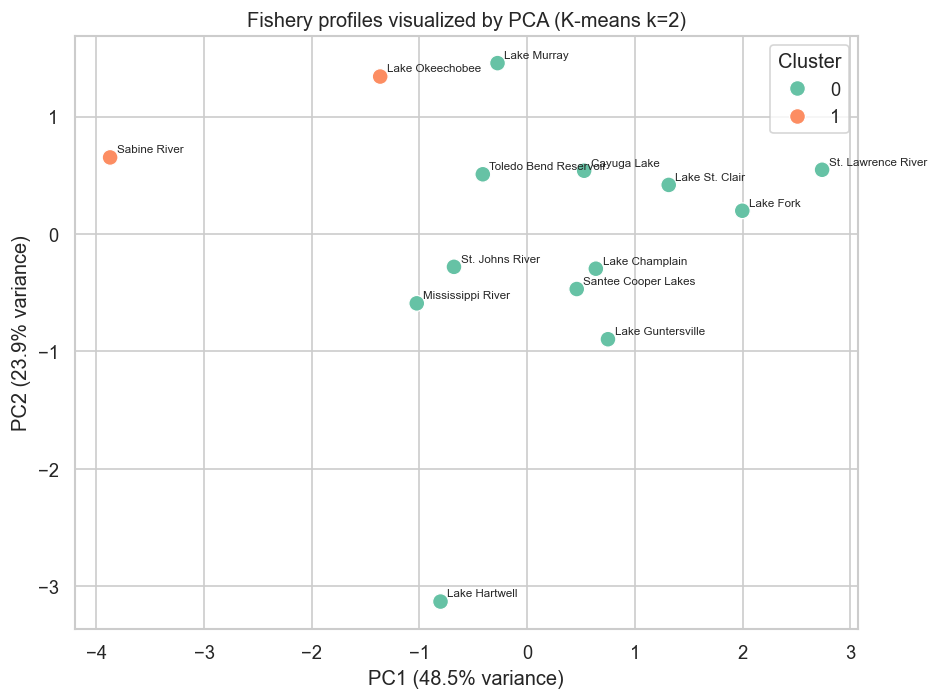

In [134]:
cluster_evaluations = []
cluster_models = {}
max_k = min(6, len(cluster_features) - 1)
for k in range(2, max_k + 1):
    model = KMeans(n_clusters=k, random_state=CLUSTER_RANDOM_STATE, n_init=50)
    labels = model.fit_predict(cluster_scaled)
    sizes = pd.Series(labels).value_counts().sort_index()
    score = silhouette_score(cluster_scaled, labels)
    cluster_models[k] = (model, labels)
    cluster_evaluations.append(
        {
            "k": k, "Silhouette": score,
            "Cluster sizes": sizes.to_dict(),
            "Smallest cluster": int(sizes.min()),
            "All clusters >=3 fisheries": bool(sizes.min() >= 3),
        }
    )
cluster_evaluation_table = pd.DataFrame(cluster_evaluations)
display(cluster_evaluation_table)

eligible_k = [
    row["k"] for row in cluster_evaluations
    if row["All clusters >=3 fisheries"]
]
if not eligible_k:
    selected_k = 2
    print("No evaluated k has all clusters >=3; no cluster solution is accepted, and k=2 is shown only as exploratory diagnostics.")
else:
    selected_k = max(
        eligible_k,
        key=lambda k: cluster_evaluation_table.loc[
            cluster_evaluation_table["k"].eq(k), "Silhouette"
        ].iloc[0],
    )
    print("Selected descriptive k among solutions with at least three fisheries per cluster:", selected_k)

selected_model, selected_labels = cluster_models[selected_k]
cluster_features["Cluster"] = selected_labels
pca = PCA(n_components=2, random_state=CLUSTER_RANDOM_STATE)
cluster_pca = pca.fit_transform(cluster_scaled)
cluster_plot = pd.DataFrame(
    {"PC1": cluster_pca[:, 0], "PC2": cluster_pca[:, 1],
     "Cluster": selected_labels, "Waterbody": cluster_input_raw.index},
    index=cluster_input_raw.index,
)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=cluster_plot, x="PC1", y="PC2", hue="Cluster", palette="Set2", s=90)
for _, row in cluster_plot.iterrows():
    plt.annotate(row["Waterbody"], (row["PC1"], row["PC2"]), xytext=(4, 3), textcoords="offset points", fontsize=7)
plt.title(f"Fishery profiles visualized by PCA (K-means k={selected_k})")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()


**Interpretation.** PCA coordinates are a two-dimensional view of standardized fishery profiles; they are not causal variables. Cluster membership describes similarities in the selected summaries, not ecological fishery types or an FFS effect.

## 9.4 Cluster validation and stability

Cluster profiles are compared using raw feature medians and FFS coverage. Stability is assessed by (a) alternative k values, (b) a K-means versus Ward agglomerative solution at the exploratory k, and (c) a reduced feature set excluding field-size and cumulative-weight features. Adjusted Rand indices compare partitions without requiring matching cluster labels.


In [135]:
cluster_features["Allowed_FFS_Coverage"] = [
    primary_events.loc[primary_events["Waterbody"].eq(w), "Allowed_FFS"].astype(str).value_counts().to_dict()
    for w in cluster_features.index
]
cluster_profile_raw = cluster_features.groupby("Cluster").agg(
    Fisheries=("N_Tournaments", "size"),
    Representative_Waterbodies=("N_Tournaments", lambda x: ", ".join(cluster_features.loc[x.index].sort_values("N_Tournaments", ascending=False).index[:5])),
    Median_Tournaments=("N_Tournaments", "median"),
    Median_Outcome=("Median_Outcome", "median"),
    Median_Outcome_IQR=("IQR_Outcome", "median"),
    Median_Cumulative_Fish=("Median_Cumulative_Fish", "median"),
    Median_Cumulative_Weight=("Median_Cumulative_Weight", "median"),
    Median_Zero_Catch_Share=("Median_Zero_Catch_Share", "median"),
    Median_Field_Size=("Median_Field_Size", "median"),
)
display(cluster_profile_raw.round(3))
display(cluster_features[["Cluster", "N_Tournaments", "N_Years", "Median_Year", "Allowed_FFS_Coverage"]].sort_values(["Cluster", "N_Tournaments"], ascending=[True, False]))

ward_labels = AgglomerativeClustering(n_clusters=selected_k, linkage="ward").fit_predict(cluster_scaled)
cluster_stability = [
    {
        "Comparison": "K-means vs Ward, same features and k",
        "Adjusted Rand index": adjusted_rand_score(selected_labels, ward_labels),
    }
]
if cluster_scaled.shape[1] >= 2:
    reduced_columns = [
        column for column in cluster_input_raw.columns
        if column not in ["Median_Field_Size", "Median_Cumulative_Weight"]
    ]
    if len(reduced_columns) >= 2:
        reduced_scaled = StandardScaler().fit_transform(cluster_input_raw[reduced_columns])
        reduced_labels = KMeans(
            n_clusters=selected_k, random_state=CLUSTER_RANDOM_STATE, n_init=50
        ).fit_predict(reduced_scaled)
        cluster_stability.append(
            {
                "Comparison": "All selected features vs reduced outcome-only profile",
                "Adjusted Rand index": adjusted_rand_score(selected_labels, reduced_labels),
            }
        )
for alternate_k in [k for k in cluster_models if k != selected_k]:
    cluster_stability.append(
        {
            "Comparison": f"k={selected_k} vs k={alternate_k}",
            "Adjusted Rand index": adjusted_rand_score(selected_labels, cluster_models[alternate_k][1]),
        }
    )
display(pd.DataFrame(cluster_stability))


,Fisheries,Representative_Waterbodies,Median_Tournaments,Median_Outcome,Median_Outcome_IQR,Median_Cumulative_Fish,Median_Cumulative_Weight,Median_Zero_Catch_Share,Median_Field_Size
Cluster,,,,,,,,,
0,12,"St. Lawrence River, St. Johns River, Lake Cham...",5.0,3.162,0.270,10.0,31.805,0.00,99.5
1,2,"Sabine River, Lake Okeechobee",4.5,2.006,0.334,10.0,21.117,0.01,103.5


,Cluster,N_Tournaments,N_Years,Median_Year,Allowed_FFS_Coverage
Waterbody,,,,,
St. Lawrence River,0,10,10,2020.0,"{'Yes (Unrestricted)': 8, 'No FFS Existed': 1,..."
St. Johns River,0,8,8,2020.0,"{'Yes (Unrestricted)': 5, 'No FFS Existed': 1,..."
Lake Champlain,0,7,6,2021.0,"{'Yes (Unrestricted)': 6, 'No': 1}"
Mississippi River,0,7,7,2018.0,"{'Yes (Unrestricted)': 4, 'No FFS Existed': 2,..."
Lake Guntersville,0,6,5,2019.5,"{'Yes (Unrestricted)': 5, 'No': 1}"
Lake Fork,0,5,5,2022.0,"{'Yes (Unrestricted)': 4, 'Yes (Restricted)': 1}"
Lake St. Clair,0,5,5,2020.0,"{'Yes (Unrestricted)': 3, 'unavailable': 1, 'Y..."
Toledo Bend Reservoir,0,5,5,2016.0,"{'No FFS Existed': 2, 'Yes (Unrestricted)': 2,..."
Santee Cooper Lakes,0,4,4,2022.5,"{'Yes (Unrestricted)': 3, 'No': 1}"


,Comparison,Adjusted Rand index
0,"K-means vs Ward, same features and k",0.568720
1,All selected features vs reduced outcome-only ...,0.671663
2,k=2 vs k=3,0.553484
3,k=2 vs k=4,0.274678
4,k=2 vs k=5,0.261702
5,k=2 vs k=6,0.138258


## 9.5 Interpretation of fishery groups

Cluster profiles are descriptive and depend on the minimum-coverage threshold and selected event features. They do not establish that a group responds similarly to FFS. Fishery-specific comparisons below require repeated events under both of the primary labels and show each tournament rather than hiding small counts behind a boxplot.


# 10. Anomaly Detection

## 10.1 Definition of an unusual tournament

An unusual event is a tournament with an unusual multivariate combination of fish-size outcome, median fish count, cumulative-weight spread, zero-catch share, winner weight, and field size. This is a review priority, not an automatic data-error label.

## 10.2 Detection method

Isolation Forest is fit at the tournament level with random state 7130. Contamination values 0.03 and 0.05 request that the fitted detector flag approximately those fractions for review; they are not estimated error rates.


In [136]:
anomaly_feature_columns = [
    "Median_Avg_Fish_Weight", "Median_Fish_Caught", "Weight_IQR_Lbs",
    "Proportion_Zero_Fish", "Winner_Weight_Lbs", "Angler_Records",
    "estimated_event_days", "median_proportion_limit",
]
anomaly_data = tournament_df.loc[
    tournament_df["Event_Name"].eq("Elite Series"),
    ["Event_Key", *anomaly_feature_columns],
].dropna().copy()
anomaly_matrix = anomaly_data[anomaly_feature_columns].to_numpy()
for contamination in ANOMALY_CONTAMINATION_LEVELS:
    detector = IsolationForest(
        contamination=contamination, random_state=RANDOM_SEED, n_estimators=300
    )
    anomaly_data[f"Anomaly_{int(contamination * 100):02d}"] = detector.fit_predict(anomaly_matrix) == -1

anomaly_flags = anomaly_data[["Event_Key", "Anomaly_03", "Anomaly_05"]]
tournament_df = tournament_df.merge(anomaly_flags, on="Event_Key", how="left", validate="one_to_one")
tournament_df[["Anomaly_03", "Anomaly_05"]] = (
    tournament_df[["Anomaly_03", "Anomaly_05"]]
    .astype("boolean")
    .fillna(False)
    .astype(bool)
)
print("Isolation Forest flags at 3% contamination:", int(tournament_df["Anomaly_03"].sum()))
print("Isolation Forest flags at 5% contamination:", int(tournament_df["Anomaly_05"].sum()))

Isolation Forest flags at 3% contamination: 4
Isolation Forest flags at 5% contamination: 7


## 10.3 Review of flagged events

Flagged events are joined to event summaries. The dataset does not contain weather observations, so a weather-shortened format cannot be confirmed from this file. A flag is not an error correction.

In [137]:
flagged_events = tournament_df.loc[
    tournament_df["Anomaly_05"],
    [
        "Event_Key", "Season_Year", "Event_Name", "Waterbody", "Allowed_FFS",
        "Median_Avg_Fish_Weight", "Median_Fish_Caught", "Weight_IQR_Lbs",
        "Proportion_Zero_Fish", "Winner_Weight_Lbs", "Angler_Records",
        "estimated_event_days", "median_proportion_limit",
    ],
].sort_values("Season_Year")
display(flagged_events)

,Event_Key,Season_Year,Event_Name,Waterbody,Allowed_FFS,Median_Avg_Fish_Weight,Median_Fish_Caught,Weight_IQR_Lbs,Proportion_Zero_Fish,Winner_Weight_Lbs,Angler_Records,estimated_event_days,median_proportion_limit
10,2013_2,2013,Elite Series,Sabine River,No FFS Existed,1.955357,5.0,13.640625,0.030000,49.3750,100,4,0.400000
29,2015_2,2015,Elite Series,Sabine River,Yes (Unrestricted),1.926136,6.0,13.046875,0.026786,50.0000,112,4,0.516667
58,2017_9,2017,Elite Series,Lake Champlain,Yes (Unrestricted),3.118750,10.0,21.937500,0.000000,58.7500,109,3,1.000000
73,2019_3,2019,Elite Series,Lake Hartwell,Yes (Unrestricted),2.231771,10.0,17.812500,0.000000,49.1875,52,3,0.666667
80,2020_1,2020,Elite Series,Lake Eufaula,Yes (Unrestricted),2.308036,8.0,11.796875,0.000000,47.3750,88,3,0.600000
82,2020_2,2020,Elite Series,Mississippi River,Yes (Unrestricted),3.043087,9.0,28.625000,0.018868,65.3125,53,3,0.600000
122,2024_2,2024,Elite Series,Lake Fork,Yes (Unrestricted),4.231250,10.0,40.750000,0.000000,130.9375,103,4,1.000000


## 10.4 Sensitivity of FFS comparisons to anomalies

The main bootstrap comparison is repeated after omitting 5%-contamination anomaly flags. This addresses sensitivity to unusual observed events; it does not claim that those events are invalid.


In [138]:
anomaly_sensitivity = summarize_bootstrap_case(
    "Primary comparison excluding 5% Isolation Forest flags",
    primary_comparison.loc[
        ~primary_comparison["Event_Key"].isin(
            tournament_df.loc[tournament_df["Anomaly_05"], "Event_Key"]
        )
    ].copy(),
)
display(pd.Series(anomaly_sensitivity).to_frame("Anomaly sensitivity"))
sensitivity_table = pd.concat(
    [sensitivity_table, pd.DataFrame([anomaly_sensitivity])],
    ignore_index=True,
)
display(sensitivity_table.round(3))


,Anomaly sensitivity
Sensitivity,Primary comparison excluding 5% Isolation Fore...
Outcome,Median_Avg_Fish_Weight
n_no_FFS,18
n_unrestricted,4
Median difference (lb/fish),0.774479
95% percentile CI low,-0.184375
95% percentile CI high,0.95625
Mean difference (lb/fish),0.460767


,Sensitivity,Outcome,n_no_FFS,n_unrestricted,Median difference (lb/fish),95% percentile CI low,95% percentile CI high,Mean difference (lb/fish)
0,Primary Elite Series; median outcome,Median_Avg_Fish_Weight,19,4,0.794,-0.180,0.959,0.497
1,Elite Series; event mean average-fish-weight s...,Mean_Avg_Fish_Weight,19,4,0.779,-0.235,0.966,0.488
2,"All event types, same clear labels",Median_Avg_Fish_Weight,22,4,0.774,-0.199,0.956,0.462
3,Waterbodies with >=2 events per label,Median_Avg_Fish_Weight,0,0,NaN,NaN,NaN,NaN
4,Estimated four-day events only,Median_Avg_Fish_Weight,19,4,0.794,-0.180,0.959,0.497
5,Primary comparison excluding 5% Isolation Fore...,Median_Avg_Fish_Weight,18,4,0.774,-0.184,0.956,0.461


# 11. Integrated Findings

## 11.1 Main evidence

The executive summary at the beginning reports the executed main tournament-level estimate and interval. The results are associational and are most informative as a description of observed events, not as the effect of individual sonar use.

## 11.2 What is consistent across methods

Read the bootstrap interval, repeated-waterbody baseline, estimated limit-completion results, and anomaly sensitivity together. The number of comparable tournaments and common fisheries/years is more important than the number of angler rows.

## 11.3 What remains uncertain

The recorded FFS rule is strongly aligned with time and scheduled fisheries. Days fished and bag limits are reconstructed estimates, and the event data do not include daily catch histories, actual device use, or all historical advancement rules. The restricted permutation is not performed unless its explicit exchangeability conditions are met.

## 11.4 Practical meaning

Differences between tournament categories can motivate further event-level data collection and rule-specific research. They should not be communicated as evidence that sonar use caused a change in catch outcome.

# 12. Limitations and Responsible Interpretation

1. **Observational design:** The estimates compare observed tournament contexts and are not causal.
2. **Rule versus use:** `Allowed_FFS` describes the event rule/competitive environment. Individual anglers’ equipment use is not recorded; FFS availability is not actual use.
3. **Calendar-time confounding:** Labels overlap strongly with year and changes in technology, participants, scheduling, and competitive practices. The compared labels share no calendar years.
4. **Waterbody scheduling:** Fisheries are not assigned randomly to rule periods; the same waterbody has limited repeated observations across categories.
5. **Shared tournament conditions and repeated anglers:** Rows within events are dependent and anglers recur. The main analysis aggregates to tournaments, but event-level bootstrap does not fully model repeated-waterbody or repeated-angler dependence.
6. **Reconstructed rather than observed days fished:** `event_days`, `days_fished`, and `bag_limit` were estimated in RStudio from the winner’s catch, place-based cut rules, minimum days implied by cumulative catch, and a ranking-consistency correction. They are an *estimated angler-specific cumulative bag limit*, not an official limit.
7. **Unidentified tied advancers:** An angler outside the top 50 who advanced to Day 3 through a tie but caught 10 or fewer cumulative fish may remain assigned two days. Catching 15 or fewer fish does not prove an angler missed Day 4, so place-based rules are still needed.
8. **Missing daily results:** Only cumulative results are available; daily catches and daily cuts are not observed.
9. **Historical rule variation:** Field cuts (top 12 through 2019, top 10 from 2020, top 50 plus ties for Day 3), Classic formats, and cancellations can vary by year and event.
10. **Weather-shortened events:** Shortened events are identified only through the estimated event duration; weather and cancellations are not recorded.
11. **Environmental data:** Weather, temperature, water clarity, fishery health, and other ecological conditions are unavailable.
12. **2026 completeness:** Nine 2026 Elite events appear in the extract, but completeness of the final season is not verified. The annual trend separates 2026.
13. **Small tournament counts:** Some FFS categories and waterbody-specific strata contain few events and cannot support reliable fishery-specific claims.

# 13. Conclusion

    In the primary Elite Series comparison, 19 tournaments labelled `No FFS Existed` and 81 labelled `Yes (Unrestricted)` differed by **+0.256 lb per fish** in the median tournament outcome (unrestricted minus no-FFS-era); the tournament bootstrap 95% percentile interval was **−0.011 to +0.492 lb per fish**. The interval includes zero, and the compared categories share no years. After excluding 5%-contamination anomaly flags, the estimate was **+0.236 lb per fish** (18 versus 75 events; interval **−0.001 to +0.458**), which does not materially change the uncertainty.

    The repeated-waterbody naive baseline contained 70 successive-visit pairs across 28 repeatedly observed fisheries, with median absolute forecast error **0.239 lb per fish**. Only two waterbodies had at least two tournaments in each primary category, and their intervals were wide. No restricted permutation was run because comparable mixed-label strata were absent. Clustering described 14 fisheries with at least three events each, but none of k=2–6 met the requirement that every cluster contain at least three fisheries; no fishery grouping is accepted.

    Estimated angler-specific cumulative limits (reconstructed in RStudio and validated on import with no fish count above its assigned limit) support a secondary outcome, `proportion_bag_limit`. Aggregated to tournaments, estimated limit completion did not differ clearly between the two labels: the median tournament mean proportion differed by −0.014 (interval −0.047 to +0.071) and the median share of anglers reaching their estimated limit by +0.016 (interval −0.193 to +0.174), unrestricted minus no-FFS-era, with tournament-bootstrap intervals including zero. All results describe tournaments under different recorded FFS-rule labels, not the causal effect of sonar. Time, waterbody scheduling, reconstructed (not observed) days fished, and event rules remain important limitations.


# Appendix

## A. Detailed event-structure audit

The event audit is displayed in Section 5.5. All event durations and angler-specific limits are reconstructed estimates.

## B. Additional sensitivity analyses

The comparison table in Section 7.4 reports the mean versus median outcome, all event types versus Elite only, anomaly exclusion, repeated-fishery restriction, and the estimated four-day subset. Section 7.5 repeats the tournament-level comparison for estimated limit completion. `Unknown`/unresolved labels remain excluded rather than reclassified.

### Fishery-level FFS coverage

Each coverage count is a count of tournaments. A waterbody is eligible for exploratory within-fishery comparison only with at least two tournaments under each primary label; two per category remains a very limited basis for inference.

In [139]:
coverage_counts = (
    primary_events.groupby(["Waterbody", "Allowed_FFS"], observed=True)
    .size().unstack(fill_value=0)
)
coverage_table = coverage_counts.reindex(columns=ffs_categories, fill_value=0)
coverage_table.insert(0, "Unique_Events", primary_events.groupby("Waterbody")["Event_Key"].nunique())
coverage_table.insert(1, "Years", primary_events.groupby("Waterbody")["Season_Year"].nunique())
coverage_table["Earliest_Year"] = primary_events.groupby("Waterbody")["Season_Year"].min()
coverage_table["Latest_Year"] = primary_events.groupby("Waterbody")["Season_Year"].max()
coverage_table["Estimated_Durations"] = primary_events.groupby("Waterbody")["estimated_event_days"].agg(
    lambda x: ", ".join(map(str, sorted(x.dropna().unique())))
)
coverage_table = coverage_table.sort_values(["Unique_Events", "Waterbody"], ascending=[False, True])
display(coverage_table)

primary_coverage = coverage_table.reindex(columns=PRIMARY_LABELS, fill_value=0)
qualifying_waterbodies = primary_coverage.index[primary_coverage.ge(2).all(axis=1)]
fishery_points = primary_comparison.loc[
    primary_comparison["Waterbody"].isin(qualifying_waterbodies)
].copy()
print("Waterbodies with >=2 tournaments in each compared category:", len(qualifying_waterbodies))
print("Tournament points in these exploratory subsets:", len(fishery_points))

Allowed_FFS,Unique_Events,Years,No FFS Existed,Yes (Unrestricted),Yes (Restricted),No,unavailable,Earliest_Year,Latest_Year,Estimated_Durations
Waterbody,,,,,,,,,,
St. Lawrence River,10,10,1,8,1,0,0,2013,2026,4
St. Johns River,8,8,1,5,1,0,1,2012,2025,4
Lake Champlain,7,6,0,6,0,1,0,2017,2026,"3, 4"
Mississippi River,7,7,2,4,1,0,0,2012,2025,"3, 4"
Lake Guntersville,6,5,0,5,0,1,0,2015,2026,4
Sabine River,6,6,1,4,1,0,0,2013,2025,4
Lake Fork,5,5,0,4,1,0,0,2020,2025,4
Lake St. Clair,5,5,0,3,1,0,1,2015,2025,4
Toledo Bend Reservoir,5,5,2,2,0,0,1,2012,2024,4


Waterbodies with >=2 tournaments in each compared category: 0
Tournament points in these exploratory subsets: 0


### Waterbody-specific tournament points

Points are individual tournaments, colored by rule label and positioned by year. The figure makes temporal separation visible and does not pool angler rows.

In [140]:
if len(fishery_points):
    g = sns.relplot(
        data=fishery_points, x="Season_Year", y="Median_Avg_Fish_Weight",
        hue="Allowed_FFS", hue_order=PRIMARY_LABELS, palette=FFS_COLORS,
        col="Waterbody", col_wrap=3, kind="scatter", s=70, height=3.0,
        facet_kws={"sharey": False, "sharex": False},
    )
    g.set_axis_labels("Season year", "Tournament median (lb per fish)")
    g.set_titles("{col_name}")
    g.fig.suptitle("Tournament-level outcomes in repeatedly observed fisheries", y=1.02)
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=45)
    plt.show()
else:
    print("No waterbody meets the exploratory minimum of two tournaments per primary FFS label.")


No waterbody meets the exploratory minimum of two tournaments per primary FFS label.


**Interpretation.** A qualifying waterbody has at least two events per label, but this remains sparse and time-confounded. The point plot shows the actual event counts and years; a single pre/post event is never presented as reliable fishery-specific evidence.

### Exploratory fishery-level differences

Bootstrap resampling is within waterbody and rule category, and each point remains one tournament. Intervals can be extremely wide; results are exploratory even when the minimum threshold is met.

In [141]:
def waterbody_bootstrap_difference(data, reps=BOOTSTRAP_REPS, seed=RANDOM_SEED):
    records = []
    local_rng = np.random.default_rng(seed)
    for waterbody, group in data.groupby("Waterbody"):
        a = group.loc[group["Allowed_FFS"].astype(str).eq(PRIMARY_LABELS[0]), "Median_Avg_Fish_Weight"].dropna().to_numpy()
        b = group.loc[group["Allowed_FFS"].astype(str).eq(PRIMARY_LABELS[1]), "Median_Avg_Fish_Weight"].dropna().to_numpy()
        if min(len(a), len(b)) < 2:
            continue
        draws = np.empty(reps)
        for i in range(reps):
            draws[i] = np.median(local_rng.choice(b, len(b), replace=True)) - np.median(
                local_rng.choice(a, len(a), replace=True)
            )
        records.append(
            {
                "Waterbody": waterbody, "n_no_FFS": len(a), "n_unrestricted": len(b),
                "Median difference (lb/fish)": np.median(b) - np.median(a),
                "95% bootstrap low": np.quantile(draws, .025),
                "95% bootstrap high": np.quantile(draws, .975),
                "Years_no_FFS": ", ".join(map(str, sorted(group.loc[group["Allowed_FFS"].astype(str).eq(PRIMARY_LABELS[0]), "Season_Year"].unique()))),
                "Years_unrestricted": ", ".join(map(str, sorted(group.loc[group["Allowed_FFS"].astype(str).eq(PRIMARY_LABELS[1]), "Season_Year"].unique()))),
            }
        )
    return pd.DataFrame(records)

fishery_differences = waterbody_bootstrap_difference(fishery_points)
display(fishery_differences.round(3))


""


## C. Reproducibility information

### Validation checks

The final checks verify event-key uniqueness, event-level consistency, finite average fish weights, nonnegative weights in the clean analysis, duplicate event–angler keys, tournament-level FFS counts, tournament-level resampling inputs, restricted-permutation overlap, clustering row uniqueness/variance, anomaly sensitivity, and the bag-limit validation checks.

In [142]:
validation = {
    "Event_Key unique in tournament_df": bool(tournament_df["Event_Key"].is_unique),
    "Maximum FFS labels per raw event": int(df.groupby("Event_Key", observed=True)["Allowed_FFS"].nunique().max()),
    "Maximum waterbodies per raw event": int(df.groupby("Event_Key", observed=True)["Waterbody"].nunique().max()),
    "No infinite Avg_Fish_Weight": bool(np.isfinite(df["Avg_Fish_Weight"].dropna()).all()),
    "No negative total weights in clean analysis": bool(
        (analysis_rows["Weight_Oz"].ge(0) & analysis_rows["Weight_Lbs_Calculated"].ge(0)).all()
    ),
    "No duplicate Event_Key + Player_ID in clean rows": bool(
        ~analysis_rows.duplicated(["Event_Key", "Player_ID"]).any()
    ),
    "Tournament-level table rows equal unique events": bool(
        len(tournament_df) == analysis_rows["Event_Key"].nunique()
    ),
    "Clustering has one row per waterbody": bool(cluster_features.index.is_unique),
    "No zero-variance columns in scaled clustering input": bool(
        cluster_input_raw.nunique().gt(1).all()
    ),
    "Anomaly sensitivity computed": bool("anomaly_sensitivity" in globals()),
    "Bootstrap used tournament arrays": bool(
        primary_bootstrap["n_a"] + primary_bootstrap["n_b"] == len(primary_comparison)
    ),
    "Required reconstruction columns present": not missing_columns,
    "Fish counts exceeding bag limits": int((df["Fish_Caught"] > df["bag_limit"]).sum()),
    "Proportions exceeding one": int((df["proportion_bag_limit"] > 1).sum()),
    "Missing reconstructed bag limits": int(df["bag_limit"].isna().sum()),
    "tournament_limit_summary has one row per event": bool(tournament_limit_summary["Event_Key"].is_unique),
    "Permutation mixed strata count": int(permutation_result.get("mixed_strata", 0)),
}
display(pd.Series(validation, name="Validation result").to_frame())
assert validation["Event_Key unique in tournament_df"]
assert validation["Fish counts exceeding bag limits"] == 0
assert validation["Proportions exceeding one"] == 0
assert validation["Missing reconstructed bag limits"] == 0
assert validation["Maximum FFS labels per raw event"] == 1
assert validation["Maximum waterbodies per raw event"] == 1
assert validation["No infinite Avg_Fish_Weight"]
assert validation["No negative total weights in clean analysis"]
assert validation["No duplicate Event_Key + Player_ID in clean rows"]
assert validation["Tournament-level table rows equal unique events"]
assert validation["Clustering has one row per waterbody"]
assert validation["No zero-variance columns in scaled clustering input"]

,Validation result
Event_Key unique in tournament_df,True
Maximum FFS labels per raw event,1
Maximum waterbodies per raw event,1
No infinite Avg_Fish_Weight,True
No negative total weights in clean analysis,True
No duplicate Event_Key + Player_ID in clean rows,True
Tournament-level table rows equal unique events,True
Clustering has one row per waterbody,True
No zero-variance columns in scaled clustering input,True
Anomaly sensitivity computed,True


In [143]:
print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", __import__("scipy").__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("Bootstrap repetitions:", BOOTSTRAP_REPS)
print("Permutation repetitions configured:", PERMUTATION_REPS)
print("Random seed:", RANDOM_SEED)
print("Dataset filename:", DATA_FILENAME)
print("Dataset dimensions:", df_raw.shape)
print("Unique tournaments retained:", tournament_df["Event_Key"].nunique())
print("Unique waterbodies retained:", tournament_df["Waterbody"].nunique())
print("Execution date:", date.today().isoformat())


Python: 3.13.1
pandas: 2.3.3
NumPy: 2.1.0
SciPy: 1.17.0
scikit-learn: 1.9.1
Bootstrap repetitions: 5000
Permutation repetitions configured: 5000
Random seed: 7130
Dataset filename: bass_with_limits.csv
Dataset dimensions: (13968, 38)
Unique tournaments retained: 150
Unique waterbodies retained: 62
Execution date: 2026-11-06
